# Data VZP: segmentace pozvaných žen (finální verze, 11 segmentů)

Souhrn segmentace z `vzp_segmentation.ipynb` (verze 2, `config/segments_vzp_v2.yaml`) a přechodů
z `vzp_segment_transitions.ipynb` v jednom notebooku, s opraveným vyhodnocením:

* **segmentační model** = 11 pravidel; pozvánka patří do prvního segmentu, jehož pravidlo platí;
* **„učení“ do konce roku 2023, test na roce 2024**: předpověď pro ženu je účast jejího segmentu
  v letech 2020–2023, srovnává se se skutečností 2024 (v původním oddílu 3 byla předpovědí model
  hazardu, ne segmenty);
* **přechody mezi segmenty** jako matice a jako orientovaný graf, plný i zúžený na pět největších
  segmentů;
* **zjištění a návrhy experimentů** pro prezentaci (`docs/vzp_segmentace/slides.md`).

Jednotka je pozvánka; v roce 2024 má každá žena právě jednu, takže tam pozvánka = žena.
Notebook ukazuje jen agregáty.

## Hlavní zjištění (stručně)

1. **11 pravidel stačí.** Účast segmentu z let 2020–2023 seřadí ženy pozvané v roce 2024 s AUROC
   0,807 (do 12 měsíců); plný model hazardu z 19 sloupců má 0,837. Segmenty tedy nesou zhruba 90 %
   rozlišovací síly modelu a jsou v čase stabilní.
2. **Účast se mezi segmenty liší 25×**: od 60 % (první pozvánka, v kontaktu se zdravotnictvím) po
   2–5 % (zkřížený dopis, odpojené, opakovaně nereagující). Předpověď z let 2020–2023 sedí do ±1,3 p. b.
   v osmi segmentech; v roce 2024 rostla účast u první pozvánky s málo kontakty (+5,1 p. b.)
   a u vypadlých 3–4 roky (+4,6 p. b.).
3. **Nepřišlo 207 tisíc žen (2024)**. 56 % z nich je ve čtyřech segmentech s účastí 3–10 %.
   59 % chodí ke gynekologovi nebo na jinou prevenci, takže je lze oslovit přes lékaře.
4. **Segmenty bez screeningu jsou „lepkavé“.** Z žen, které nepřišly a dostaly další pozvánku,
   zůstává ve stejném segmentu 56–83 %. Pohyb vede hlavně dolů, do „opakovaně nereaguje“.
   Návrat do lepšího segmentu je vzácný.
5. **První pozvánka je rozcestí.** Přijde 57 % žen v kontaktu se zdravotnictvím a 31 % žen s málo
   kontakty. Ostatní příští rok skončí hlavně u „gynekolog / jiná prevence, zvaná málokrát“ a 13 %
   žen s málo kontakty rovnou mezi odpojenými.

Podrobně v oddílu 7, návrhy experimentů v oddílu 8.

## 1 · Segmentační model (11 segmentů)

In [1]:
import importlib.util
import textwrap
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from catboost import CatBoostClassifier, Pool
from matplotlib.patches import Circle, FancyArrowPatch, FancyBboxPatch
from sklearn.metrics import log_loss, roc_auc_score

warnings.filterwarnings("ignore")
BASE = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data_vzp").exists())
OUT = BASE / "outputs" / "vzp_segmentation_final"
OUT.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 90)
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 130, "savefig.bbox": "tight"})

LABELS = ["SCREENING_3M_FLAG", "SCREENING_6M_FLAG", "SCREENING_12M_FLAG"]
HOR = ["3M", "6M", "12M"]
Y = LABELS[2]
AN = ["FIRST_INVITATION", "GP_REGISTERED", "GYN_REGISTERED_FLAG", "NEVER_SCREENED_BEFORE_FLAG"] + LABELS
BANDS = ["AGE_BAND", "GP_REG_DURATION_BAND", "GYN_REG_DURATION_BAND"]
REG = {"<2": 1, "2-5": 2, ">5": 3}
CAT = ["VZP_TERRITORIAL_AREA"]

d = pd.read_csv(BASE / "data_vzp" / "Rakhaton2026.csv.gz", low_memory=False)
d["INVITATION_DATE"] = pd.to_datetime(d.INVITATION_DATE, format="%d.%m.%Y")
for col in AN:
    d[col] = (d[col] == "A").astype(int)
d["AGE_BAND"] = d.AGE_BAND.str[:2].astype(int)
for col in BANDS[1:]:
    d[col] = d[col].map(REG).fillna(0).astype(int)
assert ((d[LABELS[0]] <= d[LABELS[1]]) & (d[LABELS[1]] <= d[LABELS[2]])).all()
d["UDALOST"] = 4 - d[LABELS].sum(axis=1)
FEATURES = [col for col in d.columns if col not in LABELS + ["INVITATION_ID", "PERSON_ID", "INVITATION_DATE", "UDALOST"]]

# odvozené sloupce pro pravidla (viz config/segments_vzp_v2.yaml)
d["BEZ_SCREENINGU"] = d.MONTHS_SINCE_LAST_SCREEN.isna().astype(int)
d["PREVENCE"] = ((d.OTHER_SCREENING_36M_CNT >= 1) | (d.DENTAL_PREVENTION_24M_CNT >= 1)
                 | (d.GP_PREVENTION_24M_CNT >= 1)).astype(int)
d["ROK"] = d.INVITATION_DATE.dt.year

SEG = yaml.safe_load(open(BASE / "config" / "segments_vzp_v2.yaml", encoding="utf-8"))["segments"]
NAZEV = {s["id"]: s["name_cs"] for s in SEG}
PORADI = [s["id"] for s in SEG]
# krátké názvy do grafů
KRATKE = {"minula_se": "Dopis se minul\nse screeningem", "prvni_pozvanka_malo_kontaktu": "1. pozvánka,\nmálo kontaktů",
          "prvni_pozvanka": "1. pozvánka,\nv kontaktu", "vypadla_3_4": "Vypadlá\n3–4 roky", "vypadla_4_plus": "Vypadlá\n4–5+ let",
          "nikdy_gynekolog_malo_zvana": "Gynekolog,\nzvaná málokrát", "nikdy_gynekolog_nereaguje": "Gynekolog,\nnereaguje",
          "nikdy_prevence_malo_zvana": "Jiná prevence,\nzvaná málokrát", "nikdy_prevence_nereaguje": "Jiná prevence,\nnereaguje",
          "nikdy_kontakt": "Bez prevence,\nv kontaktu", "odpojena": "Odpojená"}
BARVA = dict(zip(PORADI, [*plt.cm.tab10.colors, (0.2, 0.2, 0.2)]))

def prirad(df, seg):
    """Pořadí pravidel = priorita: pozvánka patří do prvního segmentu, jehož pravidlo platí."""
    out = pd.Series(pd.NA, index=df.index, dtype="object")
    for s in seg:
        mask = df.eval(s["rule"])
        if np.isscalar(mask):
            mask = pd.Series(bool(mask), index=df.index)
        out[out.isna() & mask.astype(bool)] = s["id"]
    assert out.notna().all()
    return pd.Categorical(out, categories=[s["id"] for s in seg], ordered=True)

d["SEGMENT"] = prirad(d, SEG)
UC = (d.INVITATION_DATE < "2024-01-01").values      # „učení“ 2020–2023
uc, test = d[UC], d[~UC].copy()

g_all, g_uc, g_te = (x.groupby("SEGMENT", observed=True) for x in (d, uc, test))
PREHLED = pd.DataFrame({
    "segment": [NAZEV[s] for s in PORADI],
    "pravidlo (po předchozích)": [s["rule"] for s in SEG],
    "pozvánek 2020–24": g_all.size(),
    "žen 2020–24": g_all.PERSON_ID.nunique(),
    "žen 2024": g_te.size(),
    "účast 12M 2020–23": g_uc[Y].mean(),
    "účast 12M 2024": g_te[Y].mean(),
})
PREHLED.to_csv(OUT / "segmenty_prehled.csv")
print(f"{len(d):,} pozvánek · {d.PERSON_ID.nunique():,} žen · {len(SEG)} segmentů · "
      f"učení 2020–2023: {UC.sum():,} pozvánek · test 2024: {len(test):,}")
PREHLED.style.format({"pozvánek 2020–24": "{:,}", "žen 2020–24": "{:,}", "žen 2024": "{:,}",
                      "účast 12M 2020–23": "{:.1%}", "účast 12M 2024": "{:.1%}"})

1,344,556 pozvánek · 508,527 žen · 11 segmentů · učení 2020–2023: 1,088,090 pozvánek · test 2024: 256,466


,segment,pravidlo (po předchozích),pozvánek 2020–24,žen 2020–24,žen 2024,účast 12M 2020–23,účast 12M 2024
SEGMENT,,,,,,,
minula_se,Dopis se minul se screeningem,MONTHS_SINCE_LAST_SCREEN < 24,"36,490","36,193","7,600",2.4%,2.4%
prvni_pozvanka_malo_kontaktu,"První pozvánka, málo kontaktů",FIRST_INVITATION == 1 and HEALTHCARE_CONTACT_12M_CNT < 6,"36,638","36,638","7,127",30.6%,35.7%
prvni_pozvanka,"První pozvánka, v kontaktu",FIRST_INVITATION == 1,"181,539","181,539","30,333",56.9%,59.6%
vypadla_3_4,Vypadlá z návyku (3–4 roky),MONTHS_SINCE_LAST_SCREEN <= 48,"89,631","83,138","16,167",34.2%,38.8%
vypadla_4_plus,Vypadlá z návyku (4–5+ let),MONTHS_SINCE_LAST_SCREEN > 48,"73,272","72,445","12,410",24.8%,25.7%
nikdy_gynekolog_malo_zvana,"Bez screeningu, gynekolog, zvaná málokrát",BEZ_SCREENINGU == 1 and GYN_PREVENTION_24M_CNT >= 1 and PRIOR_INVITATION_COUNT <= 6,"165,438","95,263","31,098",26.3%,27.1%
nikdy_gynekolog_nereaguje,"Bez screeningu, gynekolog, opakovaně nereaguje",BEZ_SCREENINGU == 1 and GYN_PREVENTION_24M_CNT >= 1,"75,411","35,487","19,949",9.0%,10.3%
nikdy_prevence_malo_zvana,"Bez screeningu, jiná prevence, zvaná málokrát",BEZ_SCREENINGU == 1 and PREVENCE == 1 and PRIOR_INVITATION_COUNT <= 6,"184,422","102,939","29,487",11.8%,12.7%
nikdy_prevence_nereaguje,"Bez screeningu, jiná prevence, opakovaně nereaguje",BEZ_SCREENINGU == 1 and PREVENCE == 1 and PRIOR_INVITATION_COUNT >= 7,"276,437","106,818","59,864",3.9%,5.1%


**Jak číst.** Pravidla platí v uvedeném pořadí: pozvánka spadne do prvního segmentu, jehož podmínka
platí, takže podmínka v řádku platí jen pro pozvánky, které nezachytila pravidla nad ním. Sloupec
„žen 2020–24“ počítá ženu v každém segmentu, kterým prošla (žena se mezi segmenty v čase přesouvá).
`BEZ_SCREENINGU` = žádný kód screeningu za 5 let; `PREVENCE` = jiný screening, zubní nebo praktická
prevence.

## 2 · Rozhodovací strom segmentů

Stejná pravidla nakreslená jako strom ano/ne. Funkce `strom()` je zapisuje samostatně a kontrola
ověřuje, že na všech pozvánkách dává stejné segmenty jako pravidla z YAML.

strom = pravidla na všech 1,344,556 pozvánkách


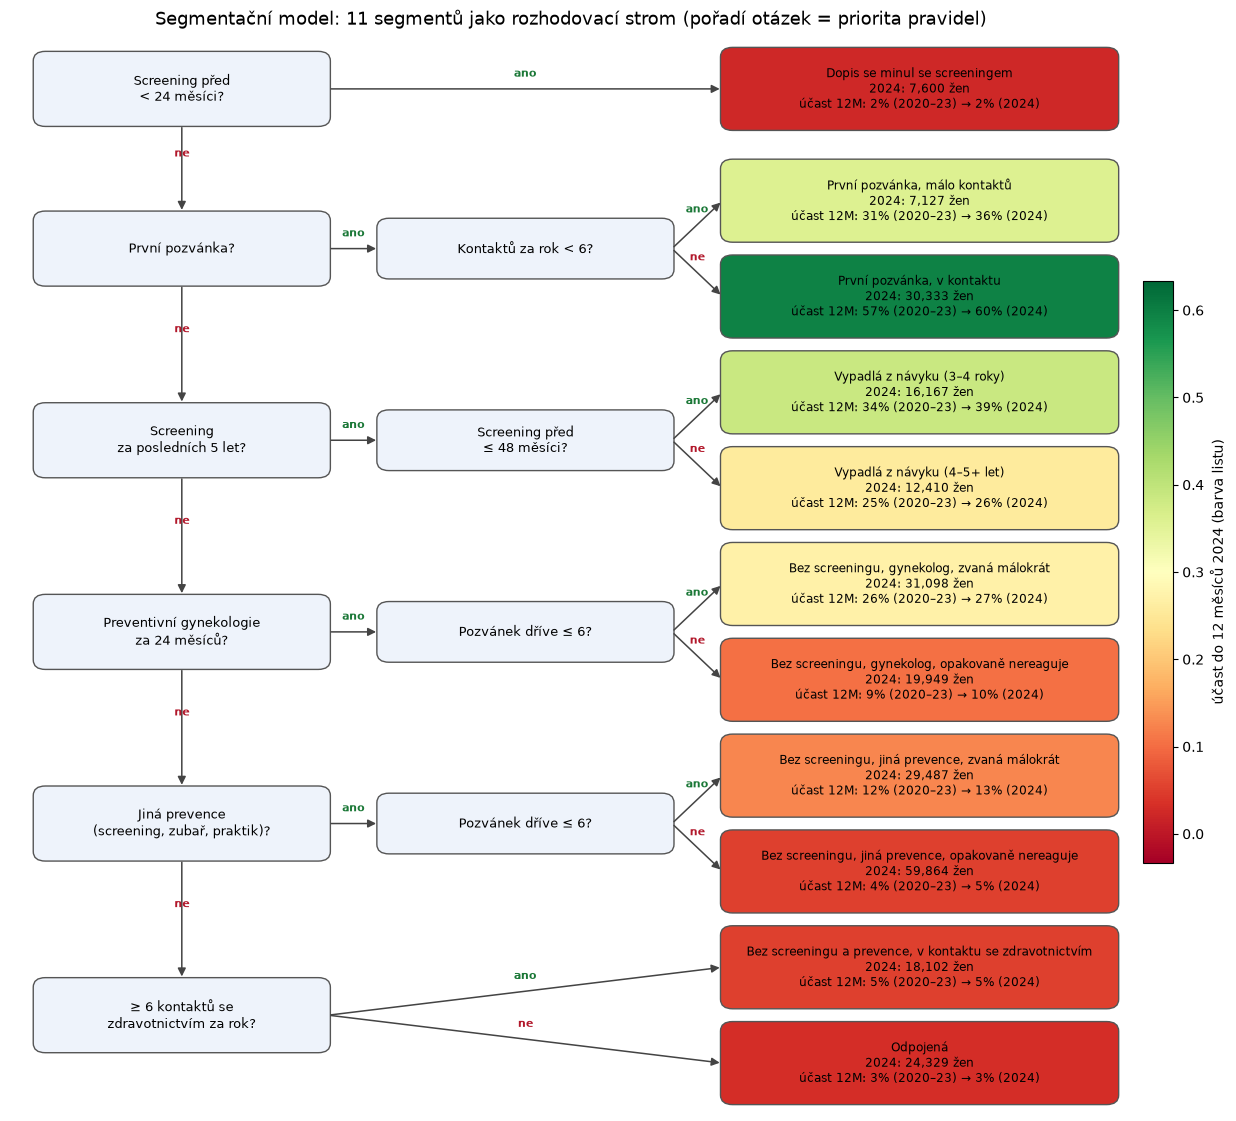

In [2]:
def strom(df):
    msls, kont = df.MONTHS_SINCE_LAST_SCREEN, df.HEALTHCARE_CONTACT_12M_CNT
    malo_zvana = df.PRIOR_INVITATION_COUNT <= 6
    podminky = [msls < 24,
                (df.FIRST_INVITATION == 1) & (kont < 6), df.FIRST_INVITATION == 1,
                msls <= 48, msls > 48,
                (df.GYN_PREVENTION_24M_CNT >= 1) & malo_zvana, df.GYN_PREVENTION_24M_CNT >= 1,
                (df.PREVENCE == 1) & malo_zvana, df.PREVENCE == 1,
                kont >= 6]
    return np.select(podminky, PORADI[:-1], PORADI[-1])

assert (strom(d) == d.SEGMENT.astype(str).values).all(), "strom a pravidla se rozcházejí"
print("strom = pravidla na všech", f"{len(d):,}", "pozvánkách")

def box(ax, x, y, text, w, h, fc, ec="#555", fs=9, bold=False):
    ax.add_patch(FancyBboxPatch((x - w / 2, y - h / 2), w, h, boxstyle="round,pad=0.02,rounding_size=0.12",
                                fc=fc, ec=ec, lw=1))
    ax.text(x, y, text, ha="center", va="center", fontsize=fs, fontweight="bold" if bold else "normal")

def sipka(ax, a, b, text, wa, wb, ha_=None):
    (x1, y1), (x2, y2) = a, b
    if abs(y1 - y2) < 1e-6:      # vodorovně
        p1, p2 = (x1 + wa / 2, y1), (x2 - wb / 2, y2)
    elif abs(x1 - x2) < 1e-6:    # svisle dolů
        p1, p2 = (x1, y1 - 0.45), (x2, y2 + 0.45)
    else:                         # šikmo doprava
        p1, p2 = (x1 + wa / 2, y1), (x2 - wb / 2, y2)
    ax.add_patch(FancyArrowPatch(p1, p2, arrowstyle="-|>", mutation_scale=12, color="#444", lw=1.1))
    ax.text((p1[0] + p2[0]) / 2, (p1[1] + p2[1]) / 2 + 0.12, text, ha="center", va="bottom", fontsize=8,
            color="#1b7837" if text == "ano" else "#b2182b", fontweight="bold")

ucast24, ucast_uc = g_te[Y].mean(), g_uc[Y].mean()
n24 = g_te.size()
cmap = plt.cm.RdYlGn
def listek(s):
    return (f"{NAZEV[s]}\n2024: {n24[s]:,} žen\núčast 12M: {ucast_uc[s]:.0%} (2020–23) → {ucast24[s]:.0%} (2024)")

WD, WL, HD, HL = 2.9, 3.9, 0.9, 1.0
XD, XS, XL = 0, 3.4, 7.3
YS = {"D1": 10, "D2": 8.0, "D3": 5.6, "D4": 3.2, "D5": 0.8, "D6": -1.6}
ROZ = 0.6
fig, ax = plt.subplots(figsize=(15, 14))
otazky = {"D1": "Screening před\n< 24 měsíci?", "D2": "První pozvánka?", "D3": "Screening\nza posledních 5 let?",
          "D4": "Preventivní gynekologie\nza 24 měsíců?", "D5": "Jiná prevence\n(screening, zubař, praktik)?",
          "D6": "≥ 6 kontaktů se\nzdravotnictvím za rok?"}
pod = {"D2": ("Kontaktů za rok < 6?", "prvni_pozvanka_malo_kontaktu", "prvni_pozvanka"),
       "D3": ("Screening před\n≤ 48 měsíci?", "vypadla_3_4", "vypadla_4_plus"),
       "D4": ("Pozvánek dříve ≤ 6?", "nikdy_gynekolog_malo_zvana", "nikdy_gynekolog_nereaguje"),
       "D5": ("Pozvánek dříve ≤ 6?", "nikdy_prevence_malo_zvana", "nikdy_prevence_nereaguje")}
klice = list(YS)
for i, k in enumerate(klice):
    y = YS[k]
    box(ax, XD, y, otazky[k], WD, HD, "#eef3fb", fs=9.5)
    if i + 1 < len(klice):
        sipka(ax, (XD, y), (XD, YS[klice[i + 1]]), "ne", WD, WD)
for k, (q, a, b) in pod.items():
    y = YS[k]
    box(ax, XS, y, q, WD, HD * 0.8, "#eef3fb", fs=9)
    sipka(ax, (XD, y), (XS, y), "ano", WD, WD)
    for s, yy, t in [(a, y + ROZ, "ano"), (b, y - ROZ, "ne")]:
        box(ax, XL, yy, listek(s), WL, HL, cmap(ucast24[s] / 0.6 * 0.9 + 0.05), fs=8.5)
        sipka(ax, (XS, y), (XL, yy), t, WD, WL)
box(ax, XL, YS["D1"], listek("minula_se"), WL, HL, cmap(ucast24["minula_se"] / 0.6 * 0.9 + 0.05), fs=8.5)
sipka(ax, (XD, YS["D1"]), (XL, YS["D1"]), "ano", WD, WL)
for s, yy, t in [("nikdy_kontakt", YS["D6"] + ROZ, "ano"), ("odpojena", YS["D6"] - ROZ, "ne")]:
    box(ax, XL, yy, listek(s), WL, HL, cmap(ucast24[s] / 0.6 * 0.9 + 0.05), fs=8.5)
    sipka(ax, (XD, YS["D6"]), (XL, yy), t, WD, WL)
ax.set_xlim(-1.7, 9.4); ax.set_ylim(-2.8, 10.7); ax.axis("off")
sm = plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(-0.033, 0.633))
plt.colorbar(sm, ax=ax, fraction=0.025, pad=0.01, label="účast do 12 měsíců 2024 (barva listu)")
ax.set_title("Segmentační model: 11 segmentů jako rozhodovací strom (pořadí otázek = priorita pravidel)", fontsize=13)
plt.savefig(OUT / "strom_segmentu.png"); plt.savefig(OUT / "strom_segmentu.svg"); plt.show()

**Jak číst.** Otázky se kladou shora dolů (svislá šipka = „ne“). Každý list je jeden segment s počtem
žen pozvaných v roce 2024 a účastí do 12 měsíců v letech 2020–2023 a v roce 2024. Barva listu
odpovídá účasti 2024 (zelená = chodí, červená = nechodí). Strom má jen tři rozměry: historii
screeningu (D1, D3), kontakt se zdravotnictvím a prevencí (D4–D6) a počet nevyslyšených pozvánek.

## 3 · Segmenty v roce 2024: model „naučený“ na 2020–2023, test na 2024

**Segmentační model** předpovídá pro každou ženu účast jejího segmentu v letech 2020–2023 (do 3, 6
a 12 měsíců). Na roce 2024 porovnáme předpověď se skutečností. Pro srovnání je tu model hazardu
z `vzp_hazard.ipynb` přeučený na **všech** pozvánkách 2020–2023 (750 iterací, nejlepší iterace
z původního běhu, bez odložené části); slouží jen jako horní mez a k měření rozptylu rizika uvnitř
segmentů. Segment do modelu hazardu nevstupuje.

In [3]:
# segmentový model: účast segmentu 2020–2023
SAZBY = g_uc[LABELS].mean()
for h, y in zip(HOR, LABELS):
    test[f"s_{h}"] = test.SEGMENT.astype(str).map(SAZBY[y].rename(index=str)).astype(float)

# model hazardu na všech pozvánkách 2020–2023
FS = FEATURES + ["INTERVAL"]
def roztahni(df):
    parts = []
    for k in (1, 2, 3):
        r = df.UDALOST >= k
        parts.append(df.loc[r, FEATURES].assign(INTERVAL=k, y=(df.UDALOST[r] == k).astype(int)))
    return pd.concat(parts)
pp = roztahni(uc)
MH = CatBoostClassifier(iterations=750, learning_rate=0.1, depth=6, thread_count=-1, random_seed=0, verbose=0)
MH.fit(Pool(pp[FS], pp.y, cat_features=CAT))
del pp
H = np.column_stack([MH.predict_proba(Pool(test[FEATURES].assign(INTERVAL=k), cat_features=CAT))[:, 1] for k in (1, 2, 3)])
F = 1 - np.cumprod(1 - H, axis=1)
for j, h in enumerate(HOR):
    test[f"p_{h}"] = F[:, j]

rows = []
for h, y in zip(HOR, LABELS):
    yt = test[y]
    rows.append({"horizont": h, "účast 2024": yt.mean(),
                 "segmenty: průměr předpovědi": test[f"s_{h}"].mean(), "segmenty: AUROC": roc_auc_score(yt, test[f"s_{h}"]),
                 "segmenty: log-loss": log_loss(yt, test[f"s_{h}"]),
                 "hazard: průměr předpovědi": test[f"p_{h}"].mean(), "hazard: AUROC": roc_auc_score(yt, test[f"p_{h}"]),
                 "hazard: log-loss": log_loss(yt, test[f"p_{h}"])})
VYKON = pd.DataFrame(rows).set_index("horizont")
VYKON.to_csv(OUT / "vykon_2024.csv")
VYKON.round(4)

,účast 2024,segmenty: průměr předpovědi,segmenty: AUROC,segmenty: log-loss,hazard: průměr předpovědi,hazard: AUROC,hazard: log-loss
horizont,,,,,,,
3M,0.0709,0.0653,0.8007,0.2144,0.0680,0.8354,0.2026
6M,0.1241,0.1153,0.8055,0.3042,0.1199,0.8363,0.2869
12M,0.1921,0.1780,0.8072,0.3871,0.1857,0.8371,0.3622


In [4]:
rows = []
for s, g in test.groupby("SEGMENT", observed=True):
    r = {"segment": NAZEV[s], "žen 2024": len(g), "podíl": len(g) / len(test)}
    for h, y in zip(HOR, LABELS):
        r[f"{h} 2020–23"] = g[f"s_{h}"].iat[0]
        r[f"{h} 2024"] = g[y].mean()
    r["rozdíl 12M (p. b.)"] = 100 * (r["12M 2024"] - r["12M 2020–23"])
    r["AUROC 12M uvnitř (hazard)"] = roc_auc_score(g[Y], g.p_12M)
    q = g.p_12M.quantile([0.1, 0.5, 0.9]).values
    r["hazard p10"], r["hazard medián"], r["hazard p90"] = q
    r["přišlo"] = int(g[Y].sum()); r["nepřišlo"] = int(len(g) - g[Y].sum())
    rows.append(r)
S24 = pd.DataFrame(rows).set_index("segment")
S24.to_csv(OUT / "segmenty_2024.csv")
pct = [col for col in S24.columns if col.startswith(("3M", "6M", "12M", "hazard", "podíl"))]
S24.style.format({"žen 2024": "{:,}", "přišlo": "{:,}", "nepřišlo": "{:,}", "rozdíl 12M (p. b.)": "{:+.1f}",
                  "AUROC 12M uvnitř (hazard)": "{:.3f}", **{col: "{:.1%}" for col in pct}})

,žen 2024,podíl,3M 2020–23,3M 2024,6M 2020–23,6M 2024,12M 2020–23,12M 2024,rozdíl 12M (p. b.),AUROC 12M uvnitř (hazard),hazard p10,hazard medián,hazard p90,přišlo,nepřišlo
segment,,,,,,,,,,,,,,,
Dopis se minul se screeningem,"7,600",3.0%,1.3%,1.5%,2.0%,2.2%,2.4%,2.4%,+0.0,0.647,0.9%,2.5%,4.9%,182,"7,418"
"První pozvánka, málo kontaktů","7,127",2.8%,10.5%,12.1%,19.8%,22.9%,30.6%,35.7%,+5.1,0.791,6.4%,32.0%,63.7%,"2,547","4,580"
"První pozvánka, v kontaktu","30,333",11.8%,24.3%,25.2%,40.5%,42.0%,56.9%,59.6%,+2.7,0.702,32.7%,64.0%,78.1%,"18,093","12,240"
Vypadlá z návyku (3–4 roky),"16,167",6.3%,12.2%,14.4%,22.0%,25.4%,34.2%,38.8%,+4.6,0.659,15.5%,34.2%,54.9%,"6,275","9,892"
Vypadlá z návyku (4–5+ let),"12,410",4.8%,8.5%,8.8%,15.3%,15.8%,24.8%,25.7%,+0.9,0.634,12.1%,23.8%,39.0%,"3,191","9,219"
"Bez screeningu, gynekolog, zvaná málokrát","31,098",12.1%,9.9%,10.6%,16.9%,17.6%,26.3%,27.1%,+0.8,0.663,14.4%,23.6%,46.5%,"8,419","22,679"
"Bez screeningu, gynekolog, opakovaně nereaguje","19,949",7.8%,3.2%,3.8%,5.5%,6.4%,9.0%,10.3%,+1.3,0.610,5.7%,8.7%,14.2%,"2,055","17,894"
"Bez screeningu, jiná prevence, zvaná málokrát","29,487",11.5%,3.0%,3.3%,6.5%,7.0%,11.8%,12.7%,+0.9,0.633,6.2%,11.6%,19.8%,"3,753","25,734"
"Bez screeningu, jiná prevence, opakovaně nereaguje","59,864",23.3%,1.0%,1.3%,2.0%,2.7%,3.9%,5.1%,+1.1,0.647,2.2%,3.8%,7.6%,"3,039","56,825"


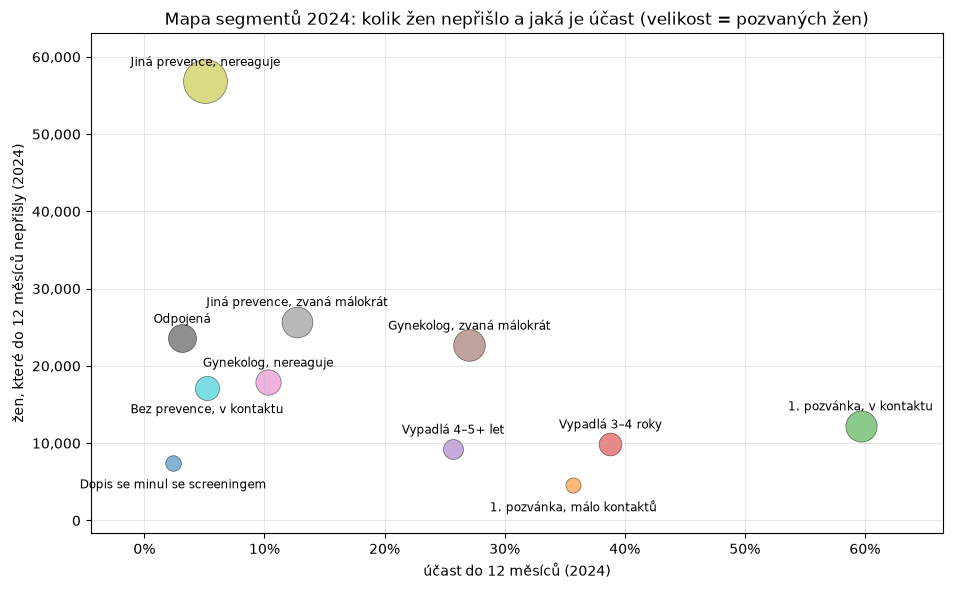

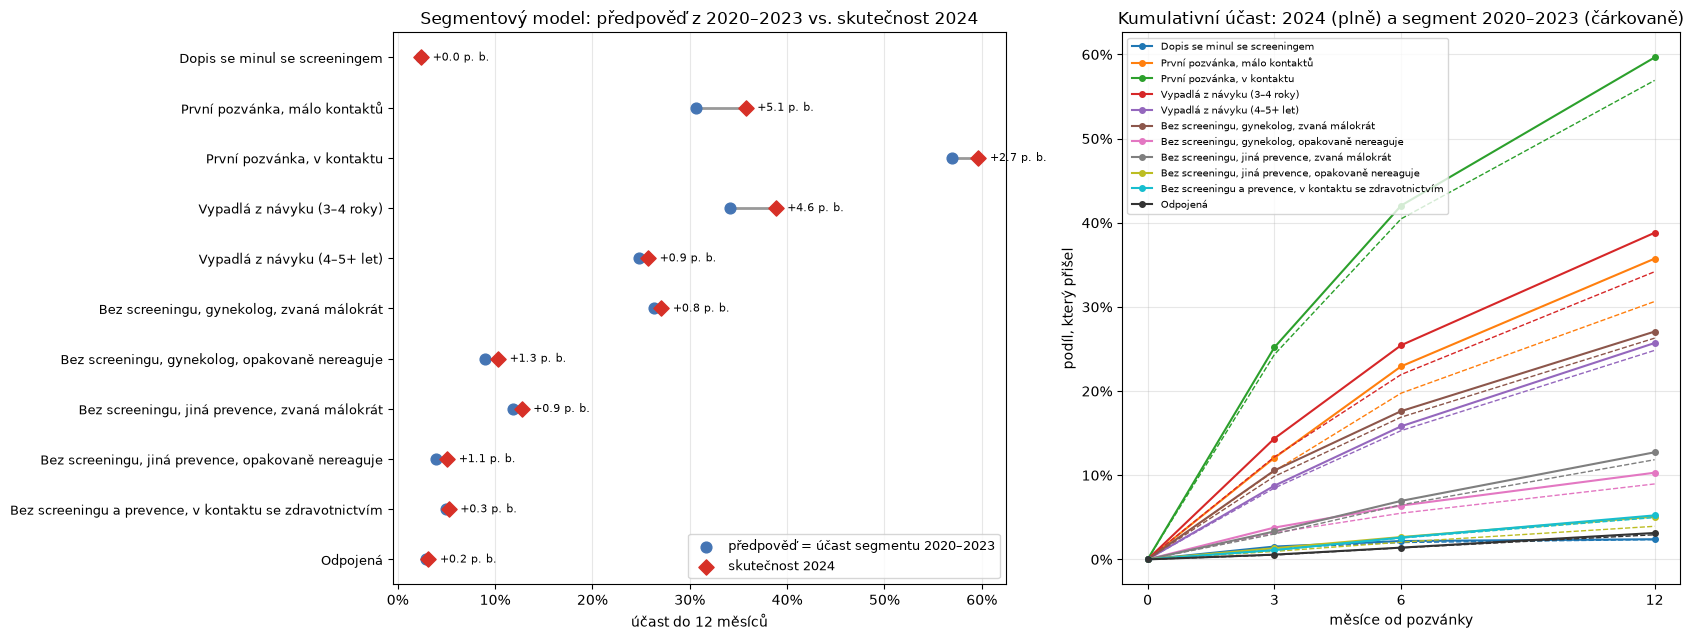

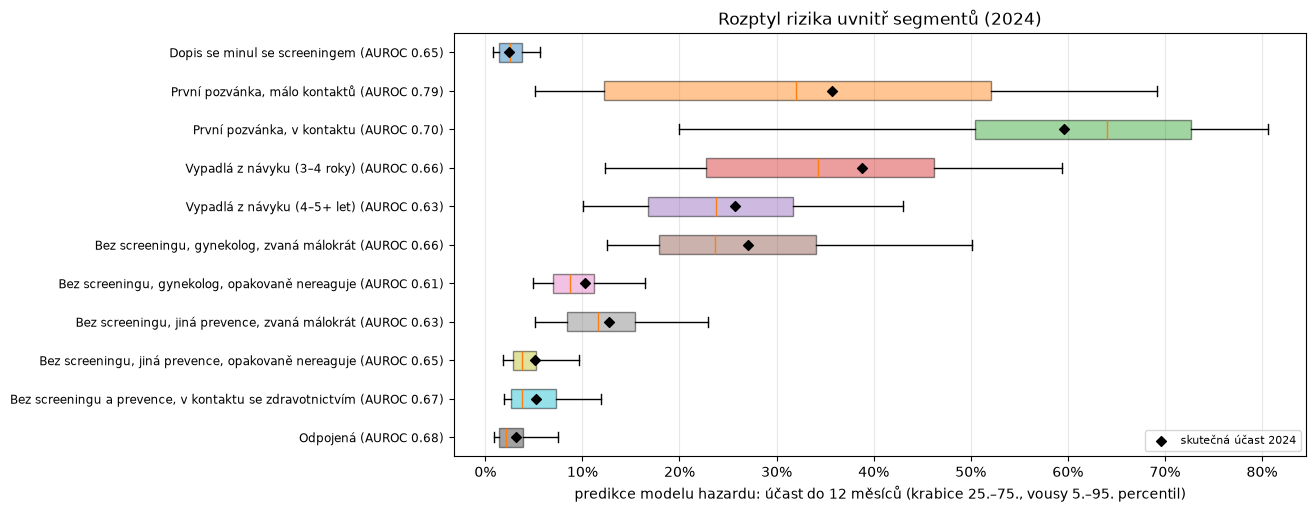

In [5]:
# mapa segmentů (velikost × účast 2024)
fig, ax = plt.subplots(figsize=(11, 6.5))
for s in PORADI:
    nm = NAZEV[s]; r = S24.loc[nm]
    ax.scatter(r["12M 2024"], r["nepřišlo"], s=r["žen 2024"] / 60, color=BARVA[s], alpha=0.55, ec="k", lw=0.5)
    dole = s in ("nikdy_kontakt", "minula_se", "prvni_pozvanka_malo_kontaktu")   # popisek pod bublinou
    ax.annotate(KRATKE[s].replace("\n", " "), (r["12M 2024"], r["nepřišlo"]), fontsize=8.5, ha="center",
                va="top" if dole else "bottom", xytext=(0, -11 if dole else 9), textcoords="offset points")
ax.set_xlabel("účast do 12 měsíců (2024)"); ax.set_ylabel("žen, které do 12 měsíců nepřišly (2024)")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.set_title("Mapa segmentů 2024: kolik žen nepřišlo a jaká je účast (velikost = pozvaných žen)")
ax.grid(alpha=0.3); ax.margins(0.12)
plt.savefig(OUT / "segmenty_mapa.png"); plt.show()

# předpověď 2020–23 vs. skutečnost 2024
fig, axes = plt.subplots(1, 2, figsize=(17, 6.5), gridspec_kw={"width_ratios": [1.1, 1]})
ax = axes[0]
yy = np.arange(len(PORADI))[::-1]
for i, s in zip(yy, PORADI):
    r = S24.loc[NAZEV[s]]
    ax.plot([r["12M 2020–23"], r["12M 2024"]], [i, i], color="#999", lw=2, zorder=1)
ax.scatter(S24["12M 2020–23"], yy, color="#4575b4", s=60, label="předpověď = účast segmentu 2020–2023", zorder=2)
ax.scatter(S24["12M 2024"], yy, color="#d73027", s=60, marker="D", label="skutečnost 2024", zorder=3)
for i, s in zip(yy, PORADI):
    r = S24.loc[NAZEV[s]]
    ax.text(max(r["12M 2020–23"], r["12M 2024"]) + 0.012, i, f"{r['rozdíl 12M (p. b.)']:+.1f} p. b.", va="center", fontsize=8)
ax.set_yticks(yy, [NAZEV[s] for s in PORADI], fontsize=9)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_xlabel("účast do 12 měsíců"); ax.legend(loc="lower right", fontsize=9); ax.grid(axis="x", alpha=0.3)
ax.set_title("Segmentový model: předpověď z 2020–2023 vs. skutečnost 2024")
ax = axes[1]
for s, g in test.groupby("SEGMENT", observed=True):
    ax.plot([0, 3, 6, 12], [0, *g[LABELS].mean()], "-o", color=BARVA[s], label=NAZEV[s], ms=4)
    ax.plot([0, 3, 6, 12], [0, *SAZBY.loc[s]], "--", color=BARVA[s], lw=1)
ax.set_xticks([0, 3, 6, 12]); ax.set_xlabel("měsíce od pozvánky"); ax.set_ylabel("podíl, který přišel")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_title("Kumulativní účast: 2024 (plně) a segment 2020–2023 (čárkovaně)")
ax.legend(fontsize=7.5, loc="upper left"); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(OUT / "segmenty_predikce_2024.png"); plt.show()

# rozptyl rizika uvnitř segmentů (model hazardu)
fig, ax = plt.subplots(figsize=(11, 5.5))
data = [g.p_12M.values for _, g in test.groupby("SEGMENT", observed=True)]
bp = ax.boxplot(data, orientation="horizontal", showfliers=False, whis=(5, 95), patch_artist=True)
for patch, s in zip(bp["boxes"], PORADI):
    patch.set_facecolor(BARVA[s]); patch.set_alpha(0.45)
ax.scatter(S24["12M 2024"], range(1, len(PORADI) + 1), color="k", marker="D", s=25, zorder=3, label="skutečná účast 2024")
ax.set_yticks(range(1, len(PORADI) + 1), [f"{NAZEV[s]} (AUROC {S24.loc[NAZEV[s], 'AUROC 12M uvnitř (hazard)']:.2f})" for s in PORADI], fontsize=8.5)
ax.invert_yaxis(); ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_xlabel("predikce modelu hazardu: účast do 12 měsíců (krabice 25.–75., vousy 5.–95. percentil)")
ax.set_title("Rozptyl rizika uvnitř segmentů (2024)"); ax.legend(loc="lower right", fontsize=8); ax.grid(axis="x", alpha=0.3)
plt.savefig(OUT / "segmenty_rozptyl.png"); plt.show()

**Jak číst.**
* **Tabulka výkonu.** Segmentový model (jedna účast na segment z let 2020–2023) má na roce 2024 AUROC
  0,801 / 0,805 / 0,807 pro 3 / 6 / 12 měsíců. Model hazardu ze všech 19 sloupců má 0,836–0,837.
  Nad úrovní náhody (0,5) tak segmenty zachytí asi 90 % toho, co rozliší model. Průměr předpovědi
  segmentů (17,8 % do 12 měsíců) je pod skutečností 2024 (19,2 %), protože účast v letech 2021–2024
  mírně rostla a rok 2020 (covid) průměr stahuje dolů.
* **Tabulka segmentů.** Sloupce „2020–23“ jsou předpověď, „2024“ skutečnost. V osmi segmentech se
  liší nejvýš o 1,3 p. b. Větší rozdíly jsou jen u první pozvánky s málo kontakty (31 % → 36 %),
  vypadlých 3–4 roky (34 % → 39 %) a první pozvánky v kontaktu (57 % → 60 %). Tam účast roste rok
  od roku a pro plánování je lepší brát poslední rok nebo trend.
* **Mapa.** Vodorovně účast, svisle počet nepřišlých žen, plocha bubliny = pozvané ženy. Nahoře
  vlevo jsou velké segmenty s nízkou účastí: nejvíc nepřišlých (opakovaně nereagující s jinou
  prevencí 56,8 tis.), ale také nejnižší šance, že zareagují. Pro intervenci jsou nejslibnější
  segmenty uprostřed: ženy u gynekologa a ženy s jinou prevencí zvané málokrát (22,7 a 25,7 tis.
  nepřišlých při účasti 27 % a 13 %).
* **Kumulativní účast.** Plné čáry jsou rok 2024, čárkované předpověď segmentu. Pořadí segmentů je ve
  všech horizontech skoro stejné. Většina žen, které přijdou, přijde do 6 měsíců.
* **Rozptyl uvnitř segmentů.** Krabice ukazují predikce modelu hazardu, kosočtverec skutečnou účast.
  Široký rozptyl mají obě první pozvánky (p10–p90: 6–64 % u málo kontaktů, 33–78 % v kontaktu),
  vypadlé 3–4 roky (15–55 %) a ženy u gynekologa zvané málokrát (14–47 %). Tam má smysl uvnitř
  segmentu dál cílit podle modelu. Úzký a nízký rozptyl mají nereagující, odpojené a ženy bez
  prevence: model v nich nenajde podskupinu, která by chodila. AUROC uvnitř segmentů je 0,61–0,79.

## 3a · Výkon segmentačního modelu podrobněji

AUROC a log-loss z tabulky výše doplňují metriky pro dvě otázky, které jsou pro VZP důležité:

* **Sedí pravděpodobnosti?** Brier score a jeho zlepšení proti předpovědi bez modelu (Brier skill score,
  referencí je jedna účast 2020–2023 pro všechny), kalibrace v celku (průměr předpovědi − skutečnost),
  kalibrační sklon (1 = ideál; < 1 = předpovědi jsou příliš rozprostřené) a ECE (průměrná vážená
  odchylka předpovědi od skutečnosti ve skupinách).
* **Najde model ty správné ženy?** AUPRC (průměrná přesnost; proti podílu přišlých), kolik přišlých
  zachytí 20 % žen s nejvyšší předpovědí (a lift proti náhodnému výběru) a jaký podíl z 30 % žen
  s nejnižší předpovědí opravdu **nepřijde**. To je situace kampaně, která oslovuje ty, kdo by jinak
  nepřišli (bez modelu je to podíl nepřišlých v celé populaci, 81 %).

Segmentový model má jen 11 různých hodnot, takže ženy se stejnou předpovědí se při výběru „horních
20 %“ berou jako skupina (uvnitř skupiny poměrně). Interval spolehlivosti je bootstrap přes ženy 2024
(200 opakování).

In [6]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, brier_score_loss, precision_recall_curve, roc_curve

def zisky(skore, y):
    """Kumulativní zisk: ženy seřazené podle skóre sestupně, stejné skóre = jedna skupina.
    Vrací (podíl žen, podíl všech y = 1 mezi nimi) v bodech mezi skupinami."""
    g = pd.DataFrame({"s": np.asarray(skore), "y": np.asarray(y)}).groupby("s").y.agg(["size", "sum"]).iloc[::-1]
    return np.r_[0, g["size"].cumsum() / g["size"].sum()], np.r_[0, g["sum"].cumsum() / g["sum"].sum()]

def zachyceno(skore, y, podil):
    x, z = zisky(skore, y)
    return float(np.interp(podil, x, z))

def ece(pred, y, kosu=20):
    """Vážená průměrná |předpověď − skutečnost| ve skupinách: u segmentů po segmentech, jinak kvantilové koše."""
    pred = pd.Series(np.asarray(pred)); y = pd.Series(np.asarray(y))
    sk = pred if pred.nunique() <= 50 else pd.qcut(pred, kosu, labels=False, duplicates="drop")
    t = pd.DataFrame({"p": pred, "y": y, "k": sk}).groupby("k").agg(p=("p", "mean"), y=("y", "mean"), n=("y", "size"))
    return float((t.n * (t.p - t.y).abs()).sum() / t.n.sum())

def sklon(pred, y):
    """Kalibrační sklon: logistická regrese skutečnosti na logit předpovědi (1 = ideál)."""
    q = np.clip(pred, 1e-6, 1 - 1e-6)
    lp = np.log(q / (1 - q)).reshape(-1, 1)
    return float(LogisticRegression(penalty=None, max_iter=1000).fit(lp, y).coef_[0, 0])

MODELY = {"segmenty": "s", "hazard": "p"}
rows = []
for h, y in zip(HOR, LABELS):
    yt = test[y].values
    ref = brier_score_loss(yt, np.full(len(yt), uc[y].mean()))       # bez modelu: jedna účast 2020–2023
    for nazev, pre in MODELY.items():
        pr = test[f"{pre}_{h}"].values
        b = brier_score_loss(yt, pr)
        rows.append({"horizont": h, "model": nazev,
                     "AUROC": roc_auc_score(yt, pr), "AUPRC": average_precision_score(yt, pr), "podíl přišlých": yt.mean(),
                     "Brier": b, "Brier skill": 1 - b / ref, "log-loss": log_loss(yt, pr),
                     "kalibrace v celku (p. b.)": 100 * (pr.mean() - yt.mean()), "kalibrační sklon": sklon(pr, yt),
                     "ECE (p. b.)": 100 * ece(pr, yt),
                     "přišlé v top 20 %": zachyceno(pr, yt, 0.2), "lift top 20 %": zachyceno(pr, yt, 0.2) / 0.2,
                     "nepřišlé mezi oslovenými (dolních 30 %)": zachyceno(-pr, 1 - yt, 0.3) * (1 - yt.mean()) / 0.3})
METRIKY = pd.DataFrame(rows).set_index(["horizont", "model"])
METRIKY.to_csv(OUT / "metriky_2024.csv")
pct = ["podíl přišlých", "Brier skill", "přišlé v top 20 %", "nepřišlé mezi oslovenými (dolních 30 %)"]
METRIKY.style.format({**{c: "{:.3f}" for c in ["AUROC", "AUPRC", "Brier", "log-loss", "kalibrační sklon"]},
                      **{c: "{:.1%}" for c in pct}, "kalibrace v celku (p. b.)": "{:+.2f}", "ECE (p. b.)": "{:.2f}",
                      "lift top 20 %": "{:.2f}×"})

In [7]:
# bootstrap 95% intervaly (12 měsíců): přes ženy 2024, 200 opakování
rng = np.random.default_rng(0)
yt, ps, ph = test[Y].values, test.s_12M.values, test.p_12M.values
B = []
for _ in range(200):
    i = rng.integers(0, len(yt), len(yt))
    a_s, a_h = roc_auc_score(yt[i], ps[i]), roc_auc_score(yt[i], ph[i])
    B.append({"AUROC segmenty": a_s, "AUROC hazard": a_h, "rozdíl AUROC (hazard − segmenty)": a_h - a_s,
              "AUPRC segmenty": average_precision_score(yt[i], ps[i]), "AUPRC hazard": average_precision_score(yt[i], ph[i]),
              "Brier segmenty": brier_score_loss(yt[i], ps[i]), "Brier hazard": brier_score_loss(yt[i], ph[i])})
B = pd.DataFrame(B)
IS = pd.DataFrame({"odhad": B.mean(), "2,5 %": B.quantile(0.025), "97,5 %": B.quantile(0.975)})
IS.to_csv(OUT / "metriky_2024_bootstrap.csv")
IS.round(4)

,odhad,"2,5 %","97,5 %"
AUROC segmenty,0.8073,0.8048,0.8093
AUROC hazard,0.8371,0.8349,0.8391
rozdíl AUROC (hazard − segmenty),0.0299,0.0290,0.0310
AUPRC segmenty,0.4693,0.4655,0.4729
AUPRC hazard,0.5782,0.5736,0.5827
Brier segmenty,0.1216,0.1208,0.1224
Brier hazard,0.1122,0.1114,0.1131


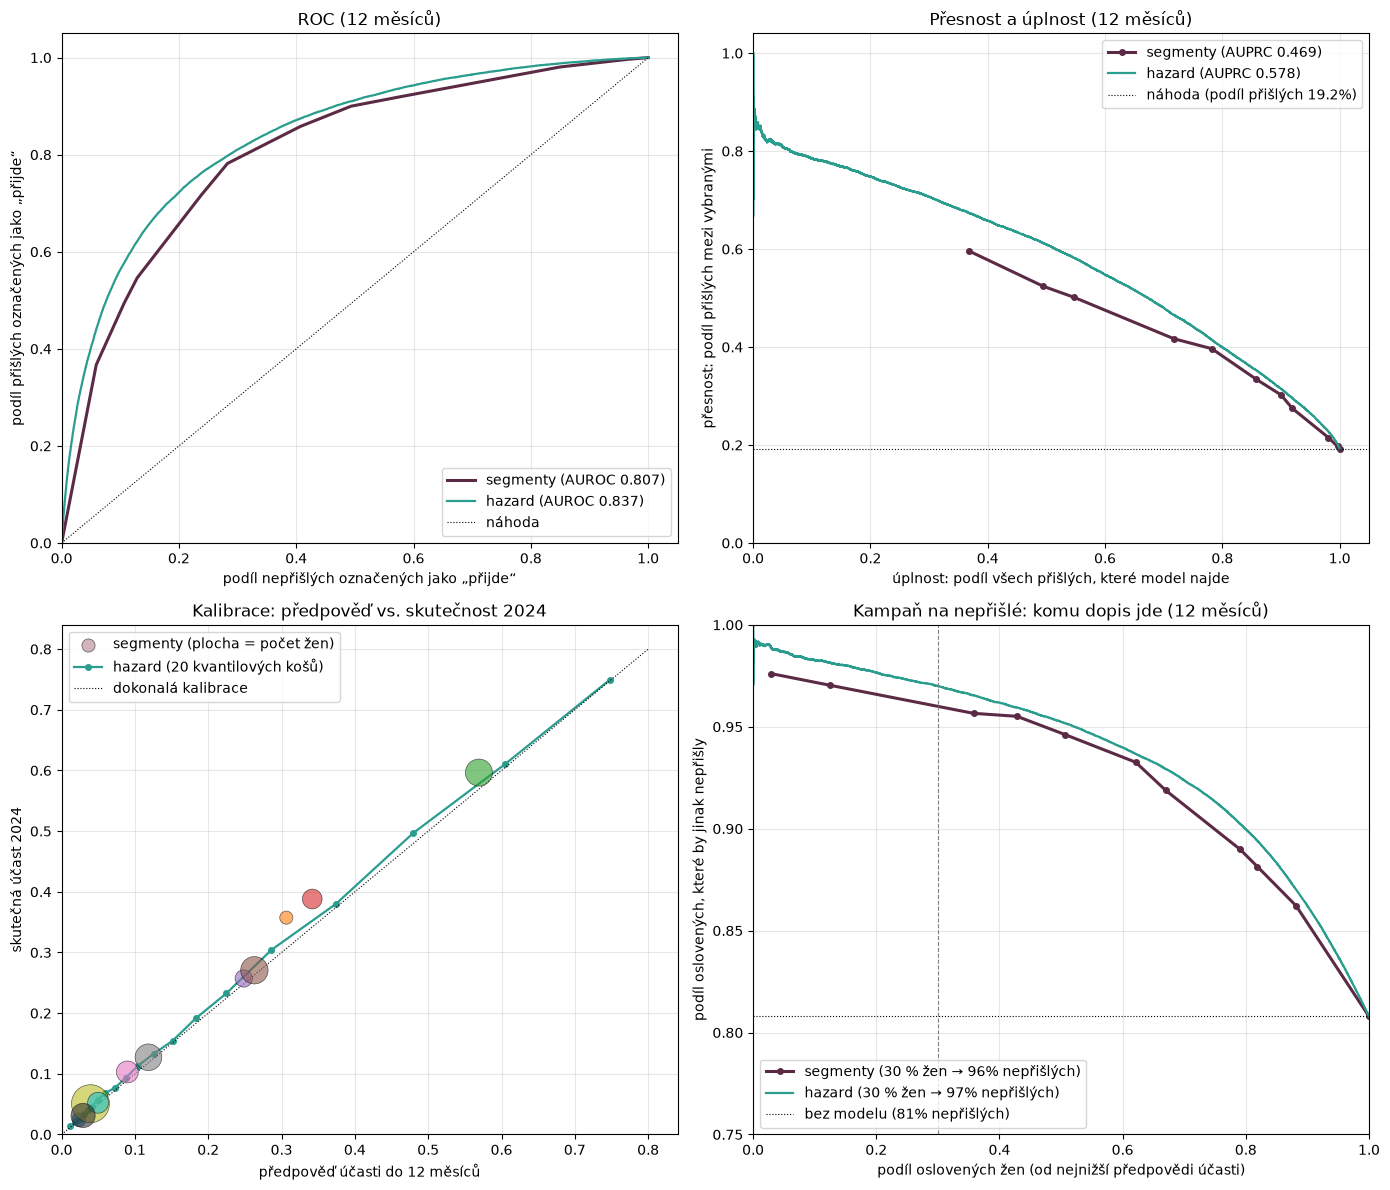

In [8]:
# grafy výkonu, 12 měsíců: ROC, přesnost–úplnost, kalibrace, kampaň na nepřišlé
yt = test[Y].values
STYL = {"segmenty": dict(color="#5B2A45", lw=2.2), "hazard": dict(color="#2A9D8F", lw=1.6)}
fig, axes = plt.subplots(2, 2, figsize=(14, 12))

ax = axes[0, 0]
for nazev, pre in MODELY.items():
    fpr, tpr, _ = roc_curve(yt, test[f"{pre}_12M"])
    ax.plot(fpr, tpr, label=f"{nazev} (AUROC {METRIKY.loc[('12M', nazev), 'AUROC']:.3f})", **STYL[nazev])
ax.plot([0, 1], [0, 1], "k:", lw=0.8, label="náhoda")
ax.set_xlabel("podíl nepřišlých označených jako „přijde“"); ax.set_ylabel("podíl přišlých označených jako „přijde“")
ax.set_title("ROC (12 měsíců)"); ax.legend(loc="lower right"); ax.grid(alpha=0.3)

ax = axes[0, 1]
for nazev, pre in MODELY.items():
    prec, rec, _ = precision_recall_curve(yt, test[f"{pre}_12M"])
    prec, rec = prec[:-1], rec[:-1]                    # bez umělého bodu (úplnost 0, přesnost 1)
    ax.plot(rec, prec, *(["o-"] if nazev == "segmenty" else []), ms=4, label=f"{nazev} (AUPRC {METRIKY.loc[('12M', nazev), 'AUPRC']:.3f})", **STYL[nazev])
ax.axhline(yt.mean(), color="k", ls=":", lw=0.8, label=f"náhoda (podíl přišlých {yt.mean():.1%})")
ax.set_xlabel("úplnost: podíl všech přišlých, které model najde"); ax.set_ylabel("přesnost: podíl přišlých mezi vybranými")
ax.set_title("Přesnost a úplnost (12 měsíců)"); ax.legend(loc="upper right"); ax.grid(alpha=0.3)

ax = axes[1, 0]
k = test.groupby("SEGMENT", observed=True).agg(p=("s_12M", "mean"), y=(Y, "mean"), n=(Y, "size"))
ax.scatter(k.p, k.y, s=k.n / 80, color=[BARVA[s] for s in k.index], alpha=0.6, ec="k", lw=0.5, zorder=3)
ax.scatter([], [], s=90, color="#B5838D", alpha=0.6, ec="k", lw=0.5, label="segmenty (plocha = počet žen)")
hk = test.assign(kos=pd.qcut(test.p_12M, 20, labels=False)).groupby("kos").agg(p=("p_12M", "mean"), y=(Y, "mean"))
ax.plot(hk.p, hk.y, "o-", ms=4, label="hazard (20 kvantilových košů)", **STYL["hazard"])
ax.plot([0, 0.8], [0, 0.8], "k:", lw=0.8, label="dokonalá kalibrace")
ax.set_xlabel("předpověď účasti do 12 měsíců"); ax.set_ylabel("skutečná účast 2024")
ax.set_title("Kalibrace: předpověď vs. skutečnost 2024"); ax.legend(loc="upper left"); ax.grid(alpha=0.3)

ax = axes[1, 1]
neprislo = 1 - yt.mean()
for nazev, pre in MODELY.items():
    x, z = zisky(-test[f"{pre}_12M"], 1 - yt)
    x, z = x[1:], z[1:]
    ax.plot(x, z * neprislo / x, *(["o-"] if nazev == "segmenty" else []), ms=4,
            label=f"{nazev} (30 % žen → {METRIKY.loc[('12M', nazev), 'nepřišlé mezi oslovenými (dolních 30 %)']:.0%} nepřišlých)",
            **STYL[nazev])
ax.axhline(neprislo, color="k", ls=":", lw=0.8, label=f"bez modelu ({neprislo:.0%} nepřišlých)")
ax.axvline(0.3, color="gray", lw=0.8, ls="--")
ax.set_xlabel("podíl oslovených žen (od nejnižší předpovědi účasti)"); ax.set_ylabel("podíl oslovených, které by jinak nepřišly")
ax.set_title("Kampaň na nepřišlé: komu dopis jde (12 měsíců)"); ax.legend(loc="lower left"); ax.grid(alpha=0.3)
ax.set_xlim(0, 1); ax.set_ylim(0.75, 1.0)
for a in axes.flat[:3]:
    a.set_xlim(0, None); a.set_ylim(0, None)
plt.tight_layout(); plt.savefig(OUT / "segmenty_vykon.png"); plt.show()

**Jak číst.**
* **Rozlišení.** Segmenty mají AUROC 0,801–0,807 (3–12 měsíců), model hazardu 0,835–0,837. Rozdíl
  na 12 měsících je 0,030 (95% interval 0,029–0,031): malý, ale jistý. Větší rozdíl ukazuje AUPRC
  (0,469 proti 0,578; bez modelu 0,192): v horní části pořadí, mezi ženami, které skoro jistě přijdou,
  má model hazardu výrazně navrch. Segmenty mají jen 11 hodnot a nejvyšší segment (první pozvánka
  v kontaktu, účast 60 %) se vybírá celý.
* **Kalibrace.** Kalibrační sklon segmentů je 0,96–0,99 (ideál 1), takže rozpětí předpovědí sedí.
  Segmenty ale účast v celku podceňují o 0,6–1,4 p. b. (do 12 měsíců o 1,4 p. b.), protože účast
  mezi lety roste; ECE (1,4 p. b.) je proto skoro celé tento posun. Model hazardu podceňuje o 0,3–0,6 p. b.
  Proti předpovědi bez modelu zlepší segmenty Brier score o 22 %, model hazardu o 28 % (12 měsíců).
* **Cílení.** 20 % žen s nejvyšší předpovědí zachytí 53 % přišlých (lift 2,6×), u modelu hazardu 58 %
  (2,9×). Pro kampaň na nepřišlé je rozdíl malý: z 30 % žen s nejnižší předpovědí by **96 %** (segmenty)
  a 97 % (hazard) jinak nepřišlo, proti 81 % bez modelu. Na výběr žen, které je třeba oslovit, segmenty
  stačí; model hazardu je lepší hlavně u žen, které přijdou samy.
* **Grafy.** ROC: segmenty jsou lomená čára s 11 vrcholy. Přesnost a úplnost: křivka segmentů začíná
  až u úplnosti 0,37, protože nejvyšší segment se bere celý. Kalibrace: body nad diagonálou jsou
  segmenty, kde účast v roce 2024 vzrostla (první pozvánky, vypadlé 3–4 roky). Vpravo dole: jaký podíl
  oslovených by jinak nepřišel, podle toho, kolik žen kampaň osloví.


## 4 · Přechodová matice segmentů (pozvánky 2020–2023)

Stejný postup jako `vzp_segment_transitions.ipynb`. Žena, která do 12 měsíců nepřijde, dostane další
dopis zhruba za rok; žena, která přijde, až po 36 a více měsících, tedy většinou mimo data. Stav po
pozvánce je proto **„přišla do 12 měsíců“**, **segment další pozvánky**, nebo **„nepřišla, další
pozvánka v datech není“**. Do matice vstupují jen pozvánky 2020–2023, u kterých je další pozvánka
v datech pozorovatelná. Řádky dávají 100 %.

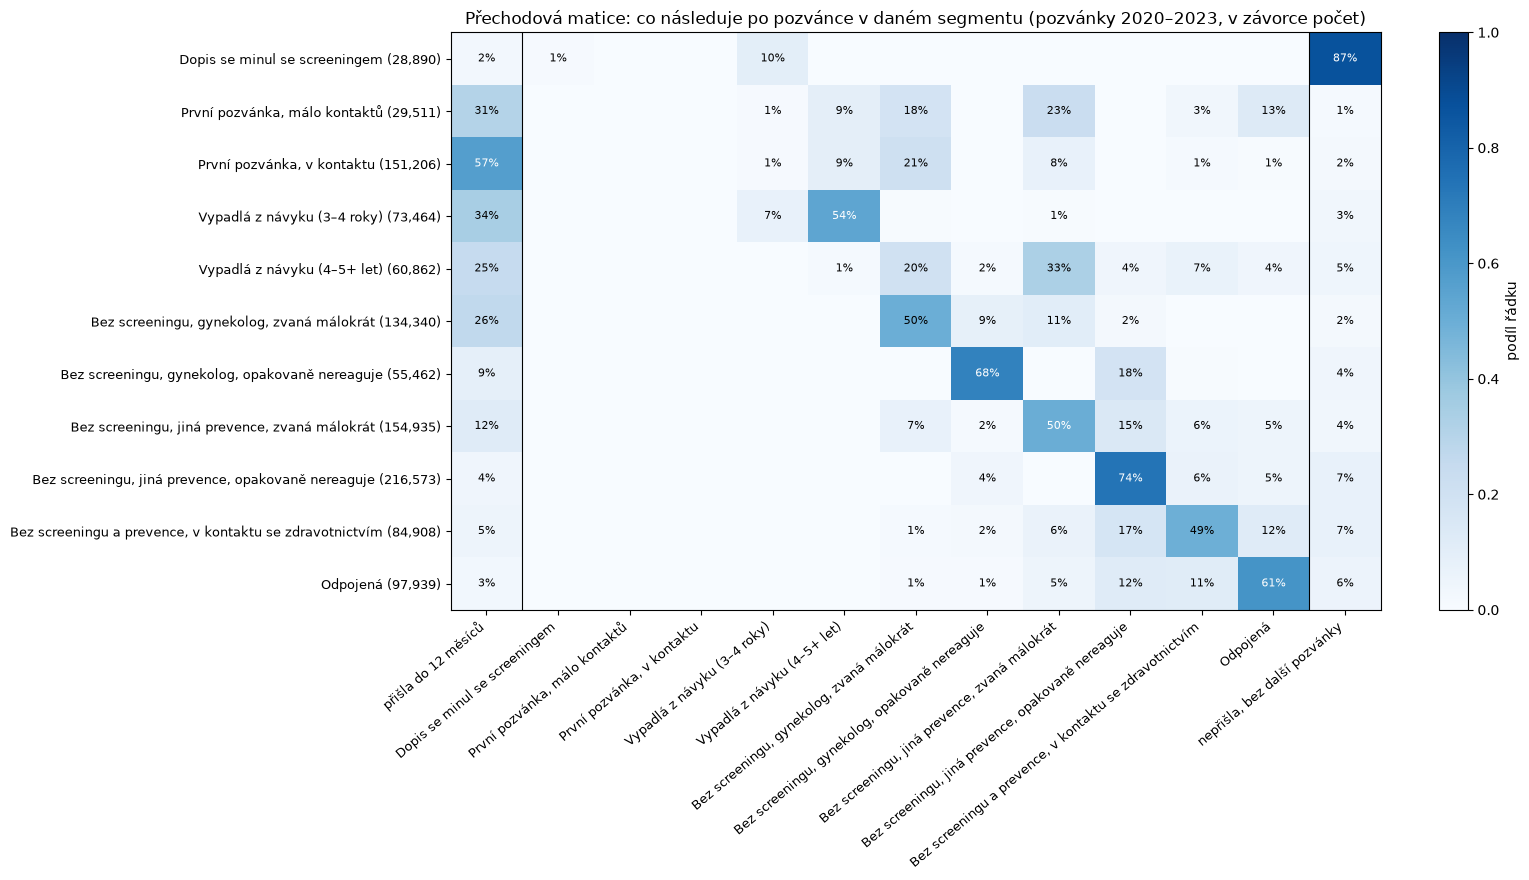

,přišla,bez další pozvánky,zůstala (z pozvaných znovu)
segment,,,
Dopis se minul se screeningem,2.4%,86.8%,9.0%
"První pozvánka, málo kontaktů",30.6%,1.3%,0.0%
"První pozvánka, v kontaktu",56.9%,2.0%,0.0%
Vypadlá z návyku (3–4 roky),34.2%,3.4%,11.3%
Vypadlá z návyku (4–5+ let),24.8%,4.5%,1.8%
"Bez screeningu, gynekolog, zvaná málokrát",26.3%,1.8%,69.3%
"Bez screeningu, gynekolog, opakovaně nereaguje",9.0%,4.1%,78.4%
"Bez screeningu, jiná prevence, zvaná málokrát",11.8%,3.5%,59.2%
"Bez screeningu, jiná prevence, opakovaně nereaguje",3.9%,7.0%,82.8%


In [9]:
PRISLA, KONEC = "přišla do 12 měsíců", "nepřišla, bez další pozvánky"
t = d[["PERSON_ID", "INVITATION_DATE", "ROK", "SEGMENT", Y]].assign(SEG=d.SEGMENT.astype(str))
t = t.sort_values(["PERSON_ID", "INVITATION_DATE"])
t["SEG_DALSI"] = t.groupby("PERSON_ID").SEG.shift(-1)
r = t[t.ROK <= 2023].copy()
r["DALE"] = np.where(r[Y] == 1, "prisla", np.where(r.SEG_DALSI.notna(), r.SEG_DALSI, "konec"))
STAVY = ["prisla"] + PORADI + ["konec"]
JMENO = {**NAZEV, "prisla": PRISLA, "konec": KONEC}
CNT = pd.crosstab(r.SEG, r.DALE).reindex(index=PORADI, columns=STAVY, fill_value=0)
MAT = CNT.div(CNT.sum(axis=1), axis=0)
assert np.allclose(MAT.sum(axis=1), 1)
ZEN = r.groupby("SEG").PERSON_ID.nunique().reindex(PORADI)    # žen 2020–2023 v segmentu
CNT.rename(index=JMENO, columns=JMENO).to_csv(OUT / "prechody_pocty.csv")
MAT.rename(index=JMENO, columns=JMENO).round(4).to_csv(OUT / "prechody_podily.csv")

fig, ax = plt.subplots(figsize=(15, 7.5))
im = ax.imshow(MAT.values, cmap="Blues", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(len(STAVY)), [JMENO[x] for x in STAVY], rotation=40, ha="right", fontsize=9)
ax.set_yticks(range(len(PORADI)), [f"{NAZEV[s]} ({CNT.loc[s].sum():,})" for s in PORADI], fontsize=9)
for i in range(MAT.shape[0]):
    for j in range(MAT.shape[1]):
        v = MAT.iat[i, j]
        if v >= 0.005:
            ax.text(j, i, f"{v:.0%}", ha="center", va="center", fontsize=8, color="white" if v > 0.5 else "black")
for j in (0.5, len(STAVY) - 1.5):
    ax.axvline(j, color="k", lw=0.8)
plt.colorbar(im, ax=ax, label="podíl řádku")
ax.set_title("Přechodová matice: co následuje po pozvánce v daném segmentu (pozvánky 2020–2023, v závorce počet)")
plt.savefig(OUT / "prechodova_matice.png"); plt.show()

# nepřišlé a pozvané znovu: kolik zůstává
n_ = r[(r[Y] == 0) & r.SEG_DALSI.notna()]
CN = pd.crosstab(n_.SEG, n_.SEG_DALSI).reindex(index=PORADI, columns=PORADI, fill_value=0)
SETRV = pd.DataFrame({"segment": [NAZEV[s] for s in PORADI],
                      "přišla": MAT.prisla.values, "bez další pozvánky": MAT.konec.values,
                      "zůstala (z pozvaných znovu)": np.diag(CN.div(CN.sum(axis=1), axis=0).values)}).set_index("segment")
SETRV.to_csv(OUT / "setrvani.csv")
SETRV.style.format("{:.1%}")

**Jak číst.** Řádek = segment při pozvánce, sloupce = co následovalo. Svislé čáry oddělují tři druhy
pokračování: přišla, segment další pozvánky, konec dat. Matice nepopisuje kalendářní rok, ale krok
„pozvánka → co dál“. Druhá tabulka shrnuje řádky: kolik žen přišlo, kolik už v datech nemá další
pozvánku a kolik z žen pozvaných znovu zůstalo ve stejném segmentu.
* **Zkřížený dopis:** 87 % už další pozvánku nemá (screening právě měly) a 10 % je za 3 roky ve
  „vypadlé 3–4 roky“. Jde o ženy, které chodí; dopis jen přišel ve špatnou chvíli.
* **První pozvánka:** nikdo v ní nezůstane (z definice). Kdo nepřijde, je příští rok hlavně
  u gynekologa (21 % / 18 %) nebo s jinou prevencí (8 % / 23 %). Z první pozvánky s málo kontakty
  jde 13 % rovnou mezi odpojené.
* **Vypadlé:** z „3–4 roky“ jde 54 % do „4–5+ let“. Z „4–5+ let“ se ženy přesouvají do segmentů
  bez screeningu (33 % jiná prevence, 20 % gynekolog). To je hlavně **artefakt pětiletého okna**:
  poslední screening z okna vypadne, chování se nemění.
* **Bez screeningu:** zůstává 56–83 % žen pozvaných znovu. Pohyb vede dolů: ze „zvané málokrát“ do
  „opakovaně nereaguje“ (gynekolog 9 %, jiná prevence 15 %), z gynekologa k jiné prevenci (18 %).

## 5 · Přechody jako orientovaný graf

Uzly jsou segmenty a dva koncové stavy, hrana vede ze segmentu při pozvánce do stavu po ní a nese
podíl řádku přechodové matice. Kreslíme jen hrany s podílem aspoň 5 %; setrvání ve stejném segmentu
(smyčka) je v popisku uzlu (↻). Plocha kruhu odpovídá počtu žen v segmentu (2020–2023), barva
účasti do 12 měsíců (2020–2023, stejná škála jako ve stromu). Koncové stavy jsou pásy nahoře a dole;
každý segment má vlastní sloupec, takže hrany do nich jsou svislé.

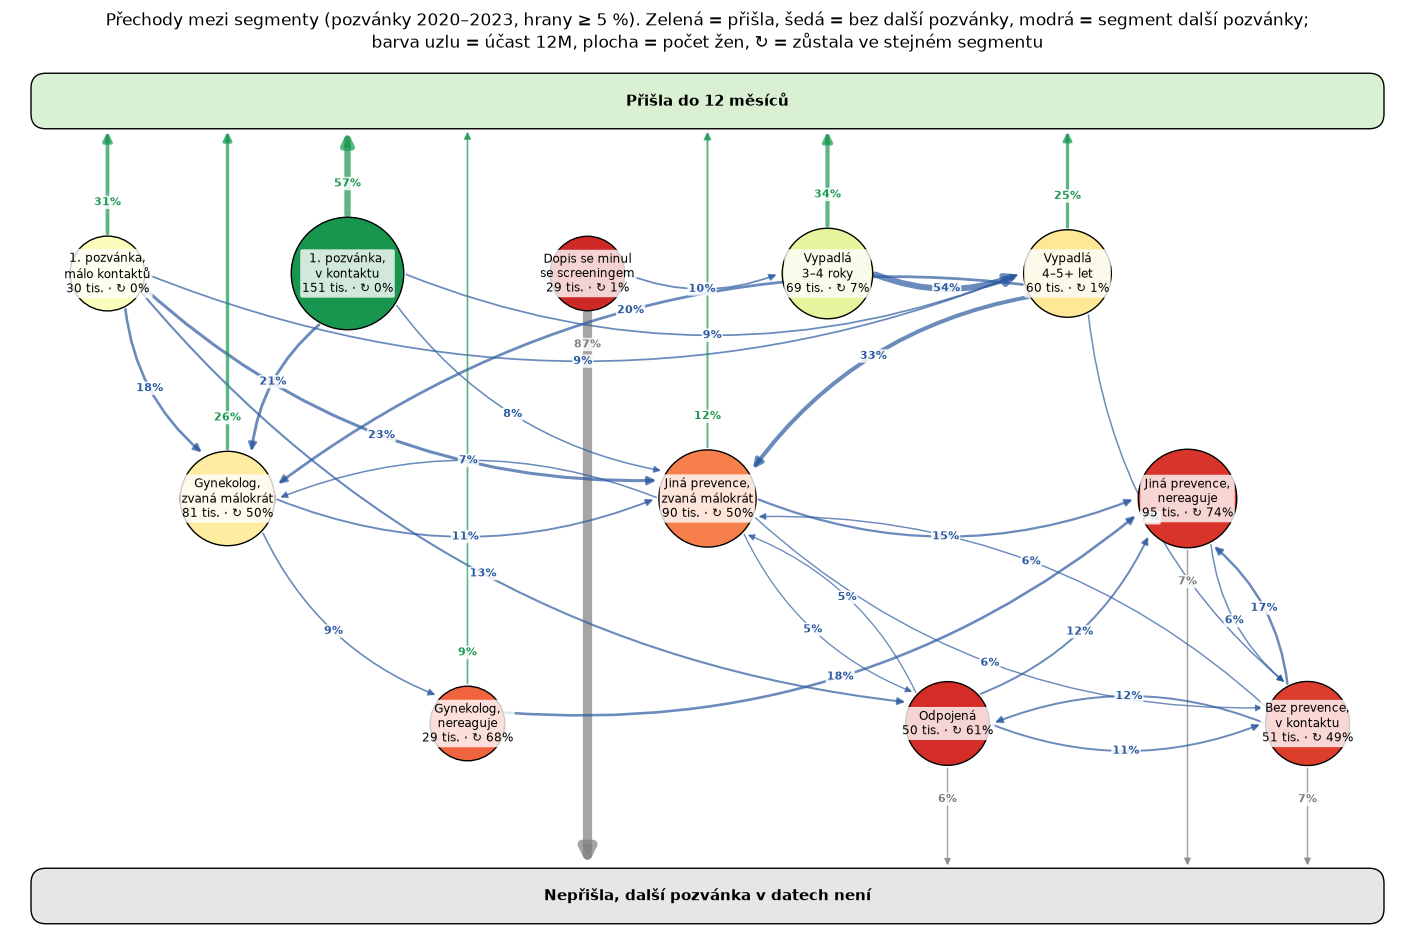

In [10]:
def bod(x1, y1, x2, y2, rad):
    """Střed kvadratické Bézierovy křivky arc3 (aspect = equal)."""
    return (x1 + x2) / 2 + 0.5 * rad * (y2 - y1), (y1 + y2) / 2 - 0.5 * rad * (x2 - x1)

def kresli_graf(ax, mat, pos, zeny, popisky, ucast, prah=0.05, rad=0.2, rmax=0.75, fs_hrana=8, fs_uzel=8.5):
    """Orientovaný graf přechodů. mat: řádky = segment při pozvánce, sloupce = stav po ní (podíly řádku);
    pos: {segment: (x, y)}, každý segment má vlastní sloupec x, takže hrany do koncových stavů
    (pásy „přišla“ nahoře a „bez další pozvánky“ dole) jsou svislé a nic nekříží."""
    xs = [p[0] for p in pos.values()]; ys = [p[1] for p in pos.values()]
    y_top, y_bot = max(ys) + 2.3, min(ys) - 2.3
    x0, x1_ = min(xs) - 1.0, max(xs) + 1.0
    rmin = 0.3
    r_ = {u: rmin + (rmax - rmin) * np.sqrt(zeny[u] / max(zeny.values())) for u in pos}
    for (yb, txt, fc) in [(y_top, "Přišla do 12 měsíců", "#d9f0d3"), (y_bot, "Nepřišla, další pozvánka v datech není", "#e6e6e6")]:
        ax.add_patch(FancyBboxPatch((x0, yb - 0.35), x1_ - x0, 0.7, boxstyle="round,pad=0.02,rounding_size=0.2",
                                    fc=fc, ec="k", lw=1, zorder=2))
        ax.text((x0 + x1_) / 2, yb, txt, ha="center", va="center", fontsize=11, fontweight="bold", zorder=5)
    for src in mat.index:
        x1, y1 = pos[src]
        for dst in mat.columns:
            v = mat.at[src, dst]
            if src == dst or v < prah:
                continue
            if dst in ("prisla", "konec"):
                up = dst == "prisla"
                a = (x1, y1 + (r_[src] if up else -r_[src])); b = (x1, (y_top - 0.37) if up else (y_bot + 0.37))
                col, rr_ = ("#1a9850" if up else "#7f7f7f"), 0.0
            else:
                x2, y2 = pos[dst]
                dx, dy = x2 - x1, y2 - y1; L = np.hypot(dx, dy)
                a = (x1 + dx / L * r_[src], y1 + dy / L * r_[src])
                b = (x2 - dx / L * (r_[dst] + 0.04), y2 - dy / L * (r_[dst] + 0.04))
                col, rr_ = "#2c5aa0", rad
            ax.add_patch(FancyArrowPatch(a, b, connectionstyle=f"arc3,rad={rr_}", arrowstyle="-|>",
                                         mutation_scale=9 + 12 * v, lw=0.6 + 7 * v, color=col, alpha=0.7, zorder=1))
            if dst in ("prisla", "konec"):   # popisek svislé hrany blízko zdroje
                mx, my = a[0], a[1] + (0.45 if dst == "prisla" else -0.45)
            else:
                mx, my = bod(*a, *b, rr_)
            ax.text(mx, my, f"{v:.0%}", fontsize=fs_hrana, ha="center", va="center", color=col, zorder=4,
                    fontweight="bold", bbox=dict(boxstyle="round,pad=0.1", fc="white", ec="none", alpha=0.85))
    for u, (x, y) in pos.items():
        fc = "#cfcfcf" if ucast[u] is None else plt.cm.RdYlGn(min(ucast[u] / 0.6, 1) * 0.9 + 0.05)
        ax.add_patch(Circle((x, y), r_[u], fc=fc, ec="k", lw=1, zorder=2))
        ax.text(x, y, popisky[u], ha="center", va="center", fontsize=fs_uzel, zorder=5,
                bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.8))
    ax.set_xlim(x0 - 0.3, x1_ + 0.3); ax.set_ylim(y_bot - 0.6, y_top + 0.6)
    ax.set_aspect("equal"); ax.axis("off")

stay = {s: MAT.at[s, s] for s in PORADI}
POPISKY = {s: f"{KRATKE[s]}\n{ZEN[s] / 1000:.0f} tis. · ↻ {stay[s]:.0%}" for s in PORADI}
# tři patra: A první pozvánka a ženy se screeningem, B bez screeningu s prevencí, C nereagující a bez prevence;
# každý segment má vlastní sloupec, takže svislé hrany do koncových stavů nekříží jiné uzly
RADY = {"A": 7.0, "B": 4.0, "C": 1.0}
ROZLOZENI = [("prvni_pozvanka_malo_kontaktu", "A"), ("nikdy_gynekolog_malo_zvana", "B"), ("prvni_pozvanka", "A"),
             ("nikdy_gynekolog_nereaguje", "C"), ("minula_se", "A"), ("nikdy_prevence_malo_zvana", "B"),
             ("vypadla_3_4", "A"), ("odpojena", "C"), ("vypadla_4_plus", "A"), ("nikdy_prevence_nereaguje", "B"),
             ("nikdy_kontakt", "C")]
POS = {s: (i * 1.6, RADY[rada]) for i, (s, rada) in enumerate(ROZLOZENI)}
fig, ax = plt.subplots(figsize=(18, 13))
kresli_graf(ax, MAT, POS, ZEN.to_dict(), POPISKY, ucast_uc.to_dict(), prah=0.05)
ax.set_title("Přechody mezi segmenty (pozvánky 2020–2023, hrany ≥ 5 %). Zelená = přišla, šedá = bez další pozvánky, "
             "modrá = segment další pozvánky;\nbarva uzlu = účast 12M, plocha = počet žen, ↻ = zůstala ve stejném segmentu",
             fontsize=12)
plt.savefig(OUT / "graf_prechodu.png"); plt.savefig(OUT / "graf_prechodu.svg"); plt.show()

**Jak číst.** Graf ukazuje stejnou matici jako oddíl 4, jen hrany pod 5 % jsou vynechané. Číslo na
hraně = podíl pozvánek ze zdrojového segmentu, které skončily v cíli. Zelené svislé hrany vedou
k účasti, šedé ke konci dat, modré do segmentu další pozvánky.
* **Horní patro** (první pozvánka, vypadlé) má silné zelené hrany: 25–57 % přijde. Zkřížený dopis
  (2 %) má jedinou silnou hranu, ke konci dat (87 %).
  Kdo nepřijde, padá modrými hranami do dolních pater.
* **Střední patro** (bez screeningu, gynekolog nebo jiná prevence, zvaná málokrát) je „čekárna“.
  Polovina žen v něm zůstává, 12–26 % přijde, zbytek odtéká do nereagujících.
* **Dolní patro** (gynekolog nereaguje, odpojené, bez prevence v kontaktu) a „jiná prevence,
  nereaguje“ tvoří uzavřený okruh. Ženy si mezi sebou předávají 6–18 % a ve stejném segmentu
  zůstává 49–74 %. Do účasti vede jen 3–9 %.

## 6 · Zúžený graf: pět největších segmentů

Pět segmentů s nejvíce ženami (unikátní ženy 2020–2024). Ostatních šest segmentů je sloučeno
do jednoho uzlu „ostatní segmenty“, takže řádky dál dávají 100 %. Hrany od 3 %.

pět největších: První pozvánka, v kontaktu, Bez screeningu, jiná prevence, opakovaně nereaguje, Bez screeningu, jiná prevence, zvaná málokrát, Bez screeningu, gynekolog, zvaná málokrát, Vypadlá z návyku (3–4 roky)


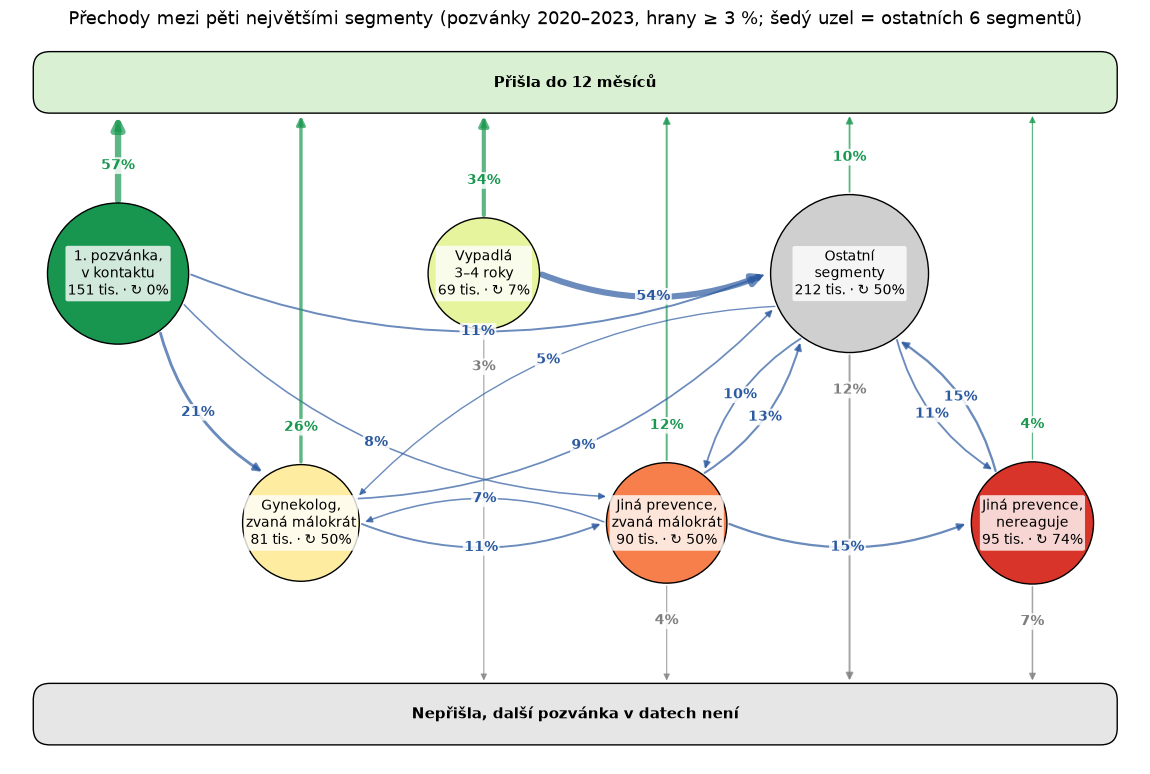

DO,přišla do 12 měsíců,"První pozvánka, v kontaktu","Bez screeningu, jiná prevence, opakovaně nereaguje","Bez screeningu, jiná prevence, zvaná málokrát","Bez screeningu, gynekolog, zvaná málokrát",Vypadlá z návyku (3–4 roky),ostatní segmenty,"nepřišla, bez další pozvánky"
Z,,,,,,,,
"První pozvánka, v kontaktu",56.9%,0.0%,0.0%,7.5%,20.9%,1.2%,11.5%,2.0%
"Bez screeningu, jiná prevence, opakovaně nereaguje",3.9%,0.0%,73.7%,0.0%,0.0%,0.0%,15.3%,7.0%
"Bez screeningu, jiná prevence, zvaná málokrát",11.8%,0.0%,14.6%,50.1%,7.4%,0.0%,12.6%,3.5%
"Bez screeningu, gynekolog, zvaná málokrát",26.3%,0.0%,2.1%,10.9%,49.8%,0.0%,9.1%,1.8%
Vypadlá z návyku (3–4 roky),34.2%,0.0%,0.2%,0.7%,0.5%,7.0%,54.0%,3.4%
ostatní segmenty,10.3%,0.0%,10.8%,10.3%,5.5%,0.9%,50.5%,11.7%


In [11]:
TOP5 = d.groupby("SEGMENT", observed=True).PERSON_ID.nunique().sort_values(ascending=False).index[:5].astype(str).tolist()
print("pět největších:", ", ".join(NAZEV[s] for s in TOP5))
OST = "ostatni"
skup = lambda x: x if x in TOP5 or x in ("prisla", "konec") else OST
rr = r.assign(Z=r.SEG.map(skup), DO=r.DALE.map(skup))
UZLY = TOP5 + [OST]
CR = pd.crosstab(rr.Z, rr.DO).reindex(index=UZLY, columns=["prisla"] + UZLY + ["konec"], fill_value=0)
MR = CR.div(CR.sum(axis=1), axis=0)
assert np.allclose(MR.sum(axis=1), 1)
ZR = rr.groupby("Z").PERSON_ID.nunique().reindex(UZLY)
MR.rename(index={**NAZEV, OST: "ostatní segmenty"}, columns={**JMENO, OST: "ostatní segmenty"}).round(4).to_csv(OUT / "prechody_top5.csv")

# rozložení: dvě patra, každý uzel vlastní sloupec
POR5 = ["prvni_pozvanka", "nikdy_gynekolog_malo_zvana", "vypadla_3_4", "nikdy_prevence_malo_zvana", OST, "nikdy_prevence_nereaguje"]
if set(POR5) != set(UZLY):   # jiná pětice: seřadit podle účasti a střídat patra
    POR5 = MR.prisla.sort_values(ascending=False).index.tolist()
POS5 = {u: (i * 2.2, 5.0 if i % 2 == 0 else 2.0) for i, u in enumerate(POR5)}
POP5 = {s: f"{KRATKE[s]}\n{ZR[s] / 1000:.0f} tis. · ↻ {MR.at[s, s]:.0%}" for s in TOP5}
POP5[OST] = f"Ostatní\nsegmenty\n{ZR[OST] / 1000:.0f} tis. · ↻ {MR.at[OST, OST]:.0%}"
U5 = {**ucast_uc.to_dict(), OST: None}
fig, ax = plt.subplots(figsize=(15, 9.5))
kresli_graf(ax, MR, POS5, ZR.to_dict(), POP5, U5, prah=0.03, rmax=0.95, fs_hrana=10, fs_uzel=10)
ax.set_title("Přechody mezi pěti největšími segmenty (pozvánky 2020–2023, hrany ≥ 3 %; šedý uzel = ostatních 6 segmentů)", fontsize=13)
plt.savefig(OUT / "graf_prechodu_top5.png"); plt.savefig(OUT / "graf_prechodu_top5.svg"); plt.show()
MR.rename(index={**NAZEV, OST: "ostatní segmenty"}, columns={**JMENO, OST: "ostatní segmenty"}).style.format("{:.1%}")

**Jak číst.** Pět největších segmentů pokrývá většinu žen. Šest menších je sloučeno do šedého uzlu.
Graf ukazuje hlavní tok populace:

**první pozvánka (57 % přijde) → gynekolog nebo jiná prevence, zvaná málokrát (26 % / 12 % přijde,
polovina zůstává) → jiná prevence, opakovaně nereaguje (4 % přijde, 74 % zůstává).**

Ze „zvané málokrát“ odtéká do „nereaguje“ každý rok 15 % žen s jinou prevencí. Zpět nevede žádná
hrana nad 3 %. Vypadlé 3–4 roky přecházejí do „ostatních“ (vypadlé 4–5+ let), odtud pak zpět do
bez screeningu.

## 7 · Hlavní zjištění

1. **Segmentace je dobrý a stabilní model.** Předpověď z let 2020–2023 (jedna účast na segment)
   seřadí ženy v roce 2024 s AUROC 0,807 do 12 měsíců (0,801 do 3 měsíců). Plný model hazardu dává
   0,837, takže 11 pravidel nese asi 90 % rozlišovací síly. Kalibrace drží v osmi segmentech do
   ±1,3 p. b. Účast roste jen u první pozvánky s málo kontakty a u vypadlých 3–4 roky (+5 p. b.).
   Kalibrační sklon je 0,99, v celku ale segmenty podceňují účast o 1,4 p. b. (účast roste). Pro
   kampaň na nepřišlé stačí: z 30 % žen s nejnižší předpovědí by 96 % jinak nepřišlo (bez modelu 81 %).
2. **Tři rozměry rozhodují:** historie screeningu (zkřížený dopis, vypadlé), kontakt se
   zdravotnictvím a prevencí (gynekolog → jiná prevence → kontakt → odpojená) a počet nevyslyšených
   pozvánek (≤ 6 / ≥ 7). Účast mezi listy stromu se liší 25× (2–60 %).
3. **Kde jsou nepřišlé ženy (2024, 207 tis.):** jiná prevence, nereaguje 27 %; jiná prevence, zvaná
   málokrát 12 %; odpojené 11 %; gynekolog, zvaná málokrát 11 %; gynekolog, nereaguje 9 %;
   bez prevence v kontaktu 8 %; první pozvánky 8 %; vypadlé 9 %; zkřížený dopis 4 %.
   **59 % nepřišlých chodí ke gynekologovi nebo na jinou prevenci.**
4. **Model hazardu uvnitř segmentů pomůže jen tam, kde je rozptyl.** U první pozvánky, vypadlých
   a gynekologa (p10–p90 široké, AUROC uvnitř 0,63–0,79) má smysl cílit podle individuálního rizika.
   U nereagujících, odpojených a žen bez prevence ne: 90 % z nich má predikci pod 15 %.
5. **Lepkavost a sestup.** Z žen bez screeningu, které nepřišly a dostaly další pozvánku, zůstává
   ve stejném segmentu 56–83 %. Každý rok sestoupí 9–15 % „zvaných málokrát“ do „opakovaně
   nereaguje“. Odtud se do účasti dostane jen 4–9 % ročně.
6. **První pozvánka je nejcennější okamžik.** Rozhoduje, jestli žena vstoupí do horního patra, nebo
   do „čekárny“ bez screeningu. Ženy s málo kontakty (36 % účast 2024) jsou nejohroženější:
   13 % z nich je příští rok odpojených.
7. **Zkřížené dopisy jsou čistá úspora.** 7 600 dopisů ročně (3 %) jde ženám, které screening měly
   0–1 měsíc předem. Účast 2 %, 87 % další pozvánku v datech nemá.
8. **Zúžený graf (pět největších segmentů):** hlavní tok populace je první pozvánka → „zvaná
   málokrát“ (gynekolog / jiná prevence) → „jiná prevence, nereaguje“. Zpětná hrana chybí.
   Intervence má smysl co nejdřív v tomto toku.

## 8 · Návrhy experimentů

Pro každý návrh: cílový segment, intervence (páky z `config/segments_vzp_v2.yaml`
a `docs/interventions.md`), výchozí účast 2024 a **nejmenší zjistitelný efekt** (MDE, absolutně
v p. b.) při individuální randomizaci, α = 0,05, síla 80 % (`utils/power.py`):
jednak když se do pokusu zařadí celý segment jednoho roku rozdělený napůl, jednak pro pilot
2 000 žen na rameno.

In [12]:
spec = importlib.util.spec_from_file_location("power", BASE / "utils" / "power.py")
power = importlib.util.module_from_spec(spec); spec.loader.exec_module(power)

EXP = [
    ("prvni_pozvanka_malo_kontaktu", "SMS / telefonát před první pozvánkou + snadné objednání",
     "osobní první kontakt zvedne účast u žen, které zdravotnictví nevidí"),
    ("prvni_pozvanka", "Dopis s informacemi pro první mamografii, sociální norma, termín k narozeninám",
     "lepší první zkušenost = návyk; zabrání přechodu do „lepkavých“ segmentů"),
    ("nikdy_gynekolog_malo_zvana", "Gynekolog dostane seznam svých pozvaných žen, žádanka při prohlídce",
     "gynekologický kanál zachytí ženy, které dopis odkládají"),
    ("nikdy_gynekolog_nereaguje", "Objednání přímo v ordinaci gynekologa místo dalšího dopisu",
     "u žen, které 7+ dopisů ignorovaly, funguje jen osobní doporučení"),
    ("nikdy_prevence_nereaguje", "Praktik při preventivní prohlídce vs. dopis; rameno bez dopisu",
     "dopis nepřináší skoro nic: ověřit náhradu kanálem praktika a non-inferioritu vynechání dopisu"),
    ("vypadla_3_4", "Připomínka s konkrétním termínem a plánem (implementation intention)",
     "ženy se zkušeností potřebují hlavně usnadnit objednání"),
]
rows = []
for s, intervence, hypo in EXP:
    nn, p0 = int(S24.loc[NAZEV[s], "žen 2024"]), S24.loc[NAZEV[s], "12M 2024"]
    rows.append({"segment": NAZEV[s], "intervence": intervence, "hypotéza": hypo, "žen 2024": nn,
                 "účast 12M 2024": p0, "nepřišlo 2024": int(S24.loc[NAZEV[s], "nepřišlo"]),
                 "MDE: celý segment napůl (p. b.)": 100 * power.mde(nn // 2, p0),
                 "MDE: 2 000 na rameno (p. b.)": 100 * power.mde(2000, p0)})
EXPT = pd.DataFrame(rows).set_index("segment")
EXPT.to_csv(OUT / "experimenty.csv")
EXPT.style.format({"žen 2024": "{:,}", "nepřišlo 2024": "{:,}", "účast 12M 2024": "{:.1%}",
                   "MDE: celý segment napůl (p. b.)": "{:.1f}", "MDE: 2 000 na rameno (p. b.)": "{:.1f}"})

,intervence,hypotéza,žen 2024,účast 12M 2024,nepřišlo 2024,MDE: celý segment napůl (p. b.),MDE: 2 000 na rameno (p. b.)
segment,,,,,,,
"První pozvánka, málo kontaktů",SMS / telefonát před první pozvánkou + snadné objednání,"osobní první kontakt zvedne účast u žen, které zdravotnictví nevidí","7,127",35.7%,"4,580",3.2,4.3
"První pozvánka, v kontaktu","Dopis s informacemi pro první mamografii, sociální norma, termín k narozeninám",lepší první zkušenost = návyk; zabrání přechodu do „lepkavých“ segmentů,"30,333",59.6%,"12,240",1.6,4.3
"Bez screeningu, gynekolog, zvaná málokrát","Gynekolog dostane seznam svých pozvaných žen, žádanka při prohlídce","gynekologický kanál zachytí ženy, které dopis odkládají","31,098",27.1%,"22,679",1.4,4.0
"Bez screeningu, gynekolog, opakovaně nereaguje",Objednání přímo v ordinaci gynekologa místo dalšího dopisu,"u žen, které 7+ dopisů ignorovaly, funguje jen osobní doporučení","19,949",10.3%,"17,894",1.2,2.8
"Bez screeningu, jiná prevence, opakovaně nereaguje",Praktik při preventivní prohlídce vs. dopis; rameno bez dopisu,dopis nepřináší skoro nic: ověřit náhradu kanálem praktika a non-inferioritu vynechání dopisu,"59,864",5.1%,"56,825",0.5,2.1
Vypadlá z návyku (3–4 roky),Připomínka s konkrétním termínem a plánem (implementation intention),ženy se zkušeností potřebují hlavně usnadnit objednání,"16,167",38.8%,"9,892",2.2,4.4


**Jak číst.** MDE je nejmenší absolutní rozdíl účasti do 12 měsíců, který pokus s danou velikostí
spolehlivě odhalí. U velkých segmentů stačí i malé efekty, takže lze testovat levné páky. U malých
segmentů (první pozvánka s málo kontakty) musí mít intervence efekt aspoň 3–4 p. b.

**Navržené experimenty (pořadí = priorita):**

1. **Opravit zkřížené dopisy** (procesní změna, ne RCT): těsně před odesláním ověřit vykázaný
   screening za poslední 2 měsíce, případně dopis odložit. Měřítko: podíl dopisů ženám se
   screeningem < 24 měsíců (dnes 3 %, 7 600 dopisů ročně). Lze vyhodnotit před/po.
2. **První pozvánka, málo kontaktů: SMS nebo telefonát** navíc k dopisu (individuální RCT, celý
   ročník napůl ≈ 3 500 žen na rameno, MDE 3,2 p. b.). Sekundárně: podíl žen, které příští rok
   skončí mezi odpojenými (dnes 13 %).
3. **První pozvánka v kontaktu: lepší dopis** (informace pro první mamografii, sociální norma,
   předvyplněný termín). Pilot 2 000 žen na rameno odhalí 4,3 p. b., celý ročník 1,6 p. b.
   Sekundárně: přechod do „gynekolog / jiná prevence, zvaná málokrát“.
4. **Gynekolog, zvaná málokrát: zapojit gynekologa** (seznam pozvaných pacientek, žádanka při
   prohlídce). Randomizovat **gynekology (klastry)**, ne ženy; MDE 1,4 p. b. platí pro individuální
   randomizaci, s klastry je třeba počítat s design efektem. Sekundárně: sestup do „nereaguje“.
5. **Gynekolog, opakovaně nereaguje: objednání přímo v ordinaci** místo dalšího dopisu (MDE
   1,2 p. b., pilot 2,8 p. b. při výchozích 10 %).
6. **Jiná prevence, opakovaně nereaguje: tři ramena.** (a) dopis jako dosud, (b) oslovení přes
   praktika při preventivní prohlídce, (c) bez dopisu. Rameno (c) je test **non-inferiority**:
   účast 5 % po 7+ dopisech naznačuje, že dopis skoro nic nepřináší a ušetřené peníze lze přesunout.
   Segment má 60 tis. žen ročně, MDE 0,5 p. b.
7. **Vypadlá 3–4 roky: připomínka s konkrétním termínem** (implementation intention, MDE 2,2 p. b.).
   Sekundárně: přechod do „4–5+ let“ (dnes 54 %).

**Společné výstupy:** účast do 3 / 6 / 12 měsíců, přechod do horšího segmentu při další pozvánce
(z přechodové matice), náklad na jednu získanou mamografii. Randomizace uvnitř segmentu
s rozvrstvením podle územního pracoviště. Analýza ITT podle `07_experiment.ipynb` v původním repozitáři.

### 8a · Pokusy v aplikaci VZP

Aplikace VZP má mezi klienty dobrý dosah (zhruba 700 tisíc uživatelů) a VZP ji chce rozvíjet jako přímý
kanál včetně zpětné vazby (dotazníky, ankety). Samotná push notifikace je slabá (`docs/interventions.md`,
položka 15); aplikace má smysl hlavně jako levný kanál pro silnější intervence a jako zdroj odpovědí
(oddíl *The VZP app as a direct channel* tamtéž). Tři návrhy, všechny s individuální randomizací
**jen mezi uživatelkami aplikace**:

* **A1 Rezervace v aplikaci:** předrezervovaný termín, který žena jedním klepnutím potvrdí, přesune
  nebo uvolní, proti dnešnímu dopisu. Cíl: první pozvánky a vypadlé 3–4 roky. Výstup: účast do 6 měsíců.
* **A2 Kanály a odkaz (faktoriál 2 × 2):** push vs. SMS a s odkazem na rezervaci vs. bez něj. Cíl: všechny
  segmenty kromě zkříženého dopisu. Výstup: účast do 12 měsíců; MDE platí pro každý hlavní efekt
  (polovina žen proti polovině).
* **A3 Dotazník bariér:** ženám, které do 3 měsíců nepřišly, krátký dotazník „Co vám brání?“ a podle
  odpovědi cílený další krok (navigace telefonem, večerní termín, doprava, „bez žádanky“) proti standardní
  připomínce. Cíl: „zvaná málokrát“ (gynekolog i jiná prevence) a vypadlé 4–5+ let. Výchozí účast je
  účast mezi 3. a 12. měsícem u žen, které do 3 měsíců nepřišly.

Podíl uživatelek aplikace mezi pozvanými ženami data neobsahují, proto MDE počítáme pro tři scénáře
(10, 20 a 30 % žen v cílových segmentech používá aplikaci) při rozdělení ročníku napůl.

In [13]:
APP_PODIL = [0.10, 0.20, 0.30]
seg = lambda ids: [NAZEV[s] for s in ids]
VSE = [s for s in PORADI if s != "minula_se"]
APP_EXP = [
    ("A1", "Rezervace v aplikaci (předrezervovaný termín, potvrzení jedním klepnutím)",
     seg(["prvni_pozvanka_malo_kontaktu", "prvni_pozvanka", "vypadla_3_4"]), "6M", False),
    ("A2", "Push vs SMS × odkaz na rezervaci (faktoriál 2 × 2, hlavní efekt)", seg(VSE), "12M", False),
    ("A3", "Dotazník bariér → cílený další krok (ženy, které do 3 měsíců nepřišly)",
     seg(["nikdy_gynekolog_malo_zvana", "nikdy_prevence_malo_zvana", "vypadla_4_plus"]), "12M", True),
]
rows = []
for kod, zasah, segmenty, h, jen_neprisle in APP_EXP:
    t = S24.loc[segmenty]
    if jen_neprisle:                    # způsobilé: nepřišly do 3 měsíců; výchozí účast mezi 3. a 12. měsícem
        n = (t["žen 2024"] * (1 - t["3M 2024"])).sum()
        p0 = (t["žen 2024"] * (t["12M 2024"] - t["3M 2024"])).sum() / n
    else:
        n = t["žen 2024"].sum()
        p0 = (t["žen 2024"] * t[f"{h} 2024"]).sum() / n
    r = {"pokus": kod, "zásah": zasah, "výstup": f"účast do {h}", "žen za rok (cílové segmenty)": int(n), "výchozí účast": p0}
    for q in APP_PODIL:
        r[f"MDE při {q:.0%} v aplikaci (p. b.)"] = 100 * power.mde(int(q * n) // 2, p0)
    rows.append(r)
APPT = pd.DataFrame(rows).set_index("pokus")
APPT.to_csv(OUT / "experimenty_aplikace.csv")
APPT.style.format({"žen za rok (cílové segmenty)": "{:,}", "výchozí účast": "{:.1%}",
                   **{c: "{:.1f}" for c in APPT.columns if c.startswith("MDE")}})

,zásah,výstup,žen za rok (cílové segmenty),výchozí účast,MDE při 10% v aplikaci (p. b.),MDE při 20% v aplikaci (p. b.),MDE při 30% v aplikaci (p. b.)
pokus,,,,,,,
A1,"Rezervace v aplikaci (předrezervovaný termín, potvrzení jedním klepnutím)",účast do 6M,"53,627",34.5%,3.7,2.6,2.1
A2,"Push vs SMS × odkaz na rezervaci (faktoriál 2 × 2, hlavní efekt)",účast do 12M,"248,866",19.7%,1.4,1.0,0.8
A3,"Dotazník bariér → cílený další krok (ženy, které do 3 měsíců nepřišly)",účast do 12M,"67,642",14.8%,2.5,1.8,1.4


**Jak číst.** MDE je nejmenší účinek, který pokus spolehlivě odhalí, když polovina uživatelek aplikace
v cílových segmentech za rok dostane zásah a polovina zůstane kontrolou (α = 0,05, síla 80 %).
* **A1 Rezervace v aplikaci:** 53,6 tis. žen za rok, výchozí účast do 6 měsíců 34,5 %. Pokus odhalí
  3,7 p. b. při 10 % v aplikaci a 2,1 p. b. při 30 %. Očekávaný přínos předrezervace je +10 až +19 p. b.,
  takže stačí i malý dosah aplikace.
* **A2 Kanály a odkaz:** 248,9 tis. žen, výchozí účast 19,7 %, MDE 0,8–1,4 p. b. Samotná push má podle
  literatury 0 až +1 p. b.; pokus tak hlavně rozhodne, zda push může nahradit SMS a kolik přidá odkaz na rezervaci.
* **A3 Dotazník bariér:** 67,6 tis. žen, které do 3 měsíců nepřišly, výchozí účast mezi 3. a 12. měsícem
  14,8 %, MDE 1,4–2,5 p. b. Vedle účasti měřit podíl odpovědí a rozložení bariér po segmentech.

Výsledky platí jen pro uživatelky aplikace. Spolu s nimi je třeba vykazovat, jaký podíl každého segmentu
aplikaci používá.


## Poznámky a omezení

* **Segmenty popisují, kdo přijde, ne kdo přijde díky intervenci.** Páky jsou hypotézy. O účinku
  rozhodne experiment (`07_experiment.ipynb` v původním repozitáři, `docs/interventions.md`).
* **Učení „do 2023“ a štítky 12M:** u pozvánek z konce roku 2023 se účast do 12 měsíců pozoruje
  až během roku 2024. Přísně oddělené učení by muselo končit v roce 2022. Pro segmentové sazby
  je vliv malý (sazby jsou stabilní), ale v ostrém provozu je třeba tento posun respektovat.
* **Model hazardu** je přeučený na všech pozvánkách 2020–2023 s pevným počtem iterací (750
  z ladění v `vzp_segmentation.ipynb`), bez vlastního ladění. Slouží jen ke srovnání a k rozptylu.
* **„Bez screeningu“ = žádný kód screeningu za posledních 5 let.** Přechod „vypadlá 4–5+ let“ →
  bez screeningu je proto částečně artefakt okna, ne změna chování.
* **Přechody** počítají jen pozvánky 2020–2023 (další pozvánka musí být v datech). Ženy, které
  přišly, dostanou další dopis až po 36+ měsících, většinou mimo data, takže „přišla“ je koncový
  stav jen v rámci těchto dat.
* **Prahy pravidel** (24 a 48 měsíců, 6 kontaktů, 6 pozvánek) jsou zvolené podle rozložení a SHAP
  v `vzp_segmentation.ipynb`, ne optimalizované.
* **V datech nejsou nově pojištěné ženy ani věk 75+.** Územní pracoviště VZP není okres.